In [1]:
# In this notebook I will analyze the genes in kegg pathways

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import mygene
import requests
import networkx as nx
import requests
import pandas as pd
import numpy as np
from matplotlib import cm

In [2]:
path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)

In [3]:
def get_antilog(df_fold_change):
    log2_fold_changes = df_fold_change['log2FoldChange']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes    
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'log2FoldChange', 'Antilog_FC',  'padj']] # 'logCPM'
    return df_fold_change

def get_foldchange(fold_change, pathways, pathway_name):
    #display(fold_change)
    try:
        display(pathways[pathways['Description']==pathway_name])
        selected_genes = pathways[pathways['Description']==pathway_name]['geneID'].str.split('/')  
        selected_genes = list(selected_genes)[0]
        print(f'The number of genes in this pathway: {len(selected_genes)}')
        selected_genes = [int(gene) for gene in selected_genes]
        selected_foldchange = fold_change[fold_change['GeneID'].isin(selected_genes)] 
        return selected_foldchange
    except:
        print('The selected pathway has a significance above 0.5 q value')    

In [4]:
mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound.csv") 
mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/Kegg_pathway.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])

spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound.csv") 
spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/Kegg_pathway.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])

FileNotFoundError: [Errno 2] No such file or directory: 'MM.control-M.wound/MM.control-M.wound.csv'

In [14]:
pathways_important_spalax_wound = ['Cytokine-cytokine receptor interaction - Mus musculus (house mouse)',
                             'JAK-STAT signaling pathway - Mus musculus (house mouse)',
                             'TNF signaling pathway - Mus musculus (house mouse)',
                             'NF-kappa B signaling pathway - Mus musculus (house mouse)',
                             'Hematopoietic cell lineage - Mus musculus (house mouse)',
                             'Viral protein interaction with cytokine and cytokine receptor - Mus musculus (house mouse)',
                             'Rheumatoid arthritis - Mus musculus (house mouse)',
                             'IL-17 signaling pathway - Mus musculus (house mouse)',
                             'Natural killer cell mediated cytotoxicity - Mus musculus (house mouse)',
                             'Inflammatory bowel disease - Mus musculus (house mouse)',
                             'Leukocyte transendothelial migration - Mus musculus (house mouse)',
                             'Adipocytokine signaling pathway - Mus musculus (house mouse)',
                             'Neutrophil extracellular trap formation - Mus musculus (house mouse)',
                             'Complement and coagulation cascades - Mus musculus (house mouse)',
                             'Osteoclast differentiation - Mus musculus (house mouse)',
                             'Pathways in cancer - Mus musculus (house mouse)',
                             'Transcriptional misregulation in cancer - Mus musculus (house mouse)']

for spalax_pathways in pathways_important_spalax_wound:
    print(f'Checking for spalax foldchange for {spalax_pathways}')
    spalax_wound_selected_foldchange=get_foldchange(spalax_wound_foldchange, spalax_wound_pathways, spalax_pathways)
    spalax_wound_selected_foldchange = spalax_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
    display(spalax_wound_selected_foldchange.head(15))
    
    print(f'Checking for mouse foldchange for {spalax_pathways}')
    mouse_wound_selected_foldchange = get_foldchange(mouse_wound_foldchange, mouse_wound_pathways, spalax_pathways)
    try:
        mouse_wound_selected_foldchange = mouse_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
        display(mouse_wound_selected_foldchange.head(15))
        plot_similar_genes(spalax_wound_selected_foldchange, mouse_wound_selected_foldchange)
    except:
        print('\n\n')
        pass

Checking for spalax foldchange for Cytokine-cytokine receptor interaction - Mus musculus (house mouse)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
0,mmu04060,Cytokine-cytokine receptor interaction - Mus m...,32/385,197/6143,4.464008e-07,0.000132,0.000115,20299/12774/56708/12985/12986/15945/227288/127...,32


The number of genes in this pathway: 32


,GeneSymbol,GeneID,logFC,Antilog_FC,PValue
167,Csf3,12985,10.224749,1196.619431,2.005193e-03
342,Il6,16193,8.902967,478.696408,1.480000e-16
491,Osm,18413,7.976595,251.880428,3.660000e-11
177,Cxcr2,12765,7.416637,170.856039,5.311279e-03
340,Il24,93672,7.208782,147.931161,1.125910e-04
176,Cxcr1,227288,7.059075,133.350115,1.380000e-09
168,Csf3r,12986,6.184737,72.743046,2.120000e-09
239,Fas,14102,5.703539,52.111841,2.900000e-07
335,Il1a,16175,5.561348,47.220730,3.590000e-05
712,Tnf,21926,5.390225,41.939121,2.920000e-06


Checking for mouse foldchange for Cytokine-cytokine receptor interaction - Mus musculus (house mouse)


...

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count


The selected pathway has a significance above 0.5 q value



Checking for spalax foldchange for Pathways in cancer - Mus musculus (house mouse)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count


The selected pathway has a significance above 0.5 q value


AttributeError: 'NoneType' object has no attribute 'sort_values'

In [10]:
pathways_important_mouse_wound = ['Cytoskeleton in muscle cells - Mus musculus (house mouse)',
                                 'Cytokine-cytokine receptor interaction - Mus musculus (house mouse)',
                                 'Hypertrophic cardiomyopathy - Mus musculus (house mouse)',
                                 'Neuroactive ligand-receptor interaction - Mus musculus (house mouse)',
                                 'Dilated cardiomyopathy - Mus musculus (house mouse)',
                                 'Staphylococcus aureus infection - Mus musculus (house mouse)',
                                 'Calcium signaling pathway - Mus musculus (house mouse)',
                                 'Viral protein interaction with cytokine and cytokine receptor - Mus musculus (house mouse)',
                                 'PPAR signaling pathway - Mus musculus (house mouse)',
                                 'Hematopoietic cell lineage - Mus musculus (house mouse)',
                                 'cAMP signaling pathway - Mus musculus (house mouse)',
                                 'Adipocytokine signaling pathway - Mus musculus (house mouse)',
                                 'Complement and coagulation cascades - Mus musculus (house mouse)',
                                 'Insulin resistance - Mus musculus (house mouse)',]

for mouse_pathways in pathways_important_mouse_wound:
    print(f'Checking for spalax foldchange for {mouse_pathways}')
    spalax_wound_selected_foldchange=get_foldchange(spalax_wound_foldchange, spalax_wound_pathways, mouse_pathways)
    try:
        spalax_wound_selected_foldchange = spalax_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
        display(spalax_wound_selected_foldchange.head(15))
    except:
        print('\n\n')
        pass
    
    print(f'Checking for mouse foldchange for {mouse_pathways}')
    mouse_wound_selected_foldchange = get_foldchange(mouse_wound_foldchange, mouse_wound_pathways, mouse_pathways)
    try:
        mouse_wound_selected_foldchange = mouse_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
        display(mouse_wound_selected_foldchange.head(15))
    except:
        print('\n\n')
        pass

Checking for spalax foldchange for Cytoskeleton in muscle cells - Mus musculus (house mouse)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count


The selected pathway has a significance above 0.5 q value



Checking for mouse foldchange for Cytoskeleton in muscle cells - Mus musculus (house mouse)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
0,mmu04820,Cytoskeleton in muscle cells - Mus musculus (h...,83/992,211/5683,1.447536e-14,4.574213e-12,4.083575e-12,11459/11465/11474/229665/78321/11928/11932/121...,83


The number of genes in this pathway: 83


...

,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count


The selected pathway has a significance above 0.5 q value



Checking for mouse foldchange for Insulin resistance - Mus musculus (house mouse)


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
23,mmu04931,Insulin resistance - Mus musculus (house mouse),29/992,101/5683,0.003266,0.043,0.038388,100705/11606/12491/12895/14936/232493/16193/16...,29


The number of genes in this pathway: 29


,GeneSymbol,GeneID,logFC,Antilog_FC,logCPM,PValue
913,Il6,16193,4.308176,19.810257,3.683598,5.250000e-06
1478,Ppp1r3b,244416,3.258569,9.570335,4.829700,1.080000e-12
1736,Slc2a1,20525,3.079789,8.454911,7.859886,3.530000e-14
1969,Tnf,21926,2.167826,4.493457,2.367866,8.400000e-05
1801,Socs3,12702,1.802495,3.488230,6.788565,1.614506e-03
2003,Trib3,228775,1.559194,2.946892,4.042897,4.717820e-04
928,Irs2,384783,-1.508883,0.351383,5.391292,2.305207e-03
1733,Slc27a1,26457,-1.724748,0.302551,4.493160,1.258740e-04
825,Gys1,14936,-1.870632,0.273454,8.049139,3.918415e-03
1290,Nr1h3,22259,-1.905132,0.266992,2.913045,2.000000e-05


In [7]:
def get_antilog(df_fold_change):
    log2_fold_changes = df_fold_change['logFC']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes    
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'logFC', 'Antilog_FC', 'logCPM', 'PValue']]
    return df_fold_change

def get_foldchange(fold_change, pathways, pathway_name):
    #display(fold_change)
    try:
        display(pathways[pathways['Description']==pathway_name])
        selected_genes = pathways[pathways['Description']==pathway_name]['geneID'].str.split('/')  
        selected_genes = list(selected_genes)[0]
        print(f'The number of genes in this pathway: {len(selected_genes)}')        
        selected_foldchange = fold_change[fold_change['GeneSymbol'].isin(selected_genes)] 
        return selected_foldchange
    except:
        print('The selected pathway has a significance above 0.5 q value')    

In [8]:
mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv") 
mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)
mouse_wound_pathways = pd.read_csv("../entrezID/MM.control-M.wound/GeneOntologyBP.csv")
mouse_wound_pathways = mouse_wound_pathways.drop(columns = ['Unnamed: 0'])

spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)
spalax_wound_pathways = pd.read_csv("../entrezID/S.control-S.wound/GeneOntologyBP.csv")
spalax_wound_pathways = spalax_wound_pathways.drop(columns = ['Unnamed: 0'])

In [9]:
pathways_important_spalax_wound = ['immune effector process',
                             'regulation of defense response',
                             'response to bacterium',
                             'innate immune response',
                             'T cell activation',
                             'regulation of inflammatory response',
                             'adaptive immune response']

for spalax_pathways in pathways_important_spalax_wound:
    print(f'Checking for spalax foldchange for {spalax_pathways}')
    spalax_wound_selected_foldchange=get_foldchange(spalax_wound_foldchange, spalax_wound_pathways, spalax_pathways)
    try:
        spalax_wound_selected_foldchange = spalax_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
        display(spalax_wound_selected_foldchange.head(15))
    except:
        print('\n\n')
        pass
    
    print(f'Checking for mouse foldchange for {spalax_pathways}')
    mouse_wound_selected_foldchange = get_foldchange(mouse_wound_foldchange, mouse_wound_pathways, spalax_pathways)
    try:
        mouse_wound_selected_foldchange = mouse_wound_selected_foldchange.sort_values(by=['Antilog_FC'], ascending=False)
        display(mouse_wound_selected_foldchange.head(15))
    except:
        print('\n\n')
        pass

Checking for spalax foldchange for immune effector process


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count
4,GO:0002252,immune effector process,111/1309,439/12251,8.506941e-19,9.126246e-16,7.099266e-16,Adora2b/Anxa1/Anxa3/Arg1/Arid5a/Arrb2/Bcl3/Cd1...,111


The number of genes in this pathway: 111


,GeneSymbol,GeneID,logFC,Antilog_FC,logCPM,PValue
601,Il6,16193,8.913252,482.121181,3.683598,2.490000e-12
886,Pglyrp1,21946,8.882539,471.966049,9.836047,3.410000e-17
1085,Slc11a1,18173,8.218230,297.806190,4.059985,4.070000e-12
1263,Tnfsf18,240873,7.672894,204.066345,0.559770,1.200000e-06
257,Clec4d,17474,7.302386,157.847373,4.153126,3.610000e-06
585,Il1b,16176,7.272036,154.561381,7.709144,5.210000e-10
83,Arg1,11846,7.028824,130.583055,8.507077,8.430000e-14
421,Fas,14102,5.733105,53.190818,4.144229,1.280000e-12
595,Il23r,209590,5.629373,49.500561,-0.635533,7.535320e-04
582,Il18rap,16174,5.457481,43.940537,2.354849,1.140000e-05


Checking for mouse foldchange for immune effector process


...

The number of genes in this pathway: 71


,GeneSymbol,GeneID,logFC,Antilog_FC,logCPM,PValue
601,Il6,16193,8.913252,482.121181,3.683598,2.490000e-12
1085,Slc11a1,18173,8.218230,297.806190,4.059985,4.070000e-12
1263,Tnfsf18,240873,7.672894,204.066345,0.559770,1.200000e-06
257,Clec4d,17474,7.302386,157.847373,4.153126,3.610000e-06
585,Il1b,16176,7.272036,154.561381,7.709144,5.210000e-10
131,Bmx,12169,7.126216,139.702646,4.409268,8.570000e-13
83,Arg1,11846,7.028824,130.583055,8.507077,8.430000e-14
1044,Samsn1,67742,5.980889,63.157808,5.683876,5.420000e-10
421,Fas,14102,5.733105,53.190818,4.144229,1.280000e-12
1201,Tarm1,245126,5.650750,50.239494,3.105542,1.110000e-05


Checking for mouse foldchange for adaptive immune response


,ID,Description,GeneRatio,BgRatio,pvalue,p.adjust,qvalue,geneID,Count


The selected pathway has a significance above 0.5 q value





### We used top 2 significant pathways, and BPs with the most number of genes, merged the list and made a network and computed the upstream transcription factors


['Ccl22', 'Ccr5', 'Clcf1', 'Csf3', 'Csf3r', 'Cxcl10', 'Cxcr1', 'Cxcr2', 'Cxcr4', 'Fas', 'Il13ra2', 'Il17ra', 'Il18r1', 'Il1a', 'Il1f10', 'Il1r1', 'Il1rn', 'Il22ra1', 'Il24', 'Il33', 'Il6', 'Inhba', 'Lep', 'Lepr', 'Lif', 'Osm', 'Prlr', 'Tgfb3', 'Tnf', 'Tnfrsf21', 'Tnfsf12', 'Tslp', 'Abcd2', 'Acod1', 'Adamts4', 'Adamts9', 'Adipoq', 'Bcl3', 'Bdkrb1', 'Cd14', 'Cd68', 'Cd86', 'Cfb', 'Cfd', 'Clec4e', 'Cnr2', 'Cxcl10', 'Dmbt1', 'Fabp4', 'Tent5a', 'Cyrib', 'Gch1', 'Hck', 'Il1a', 'Il1f10', 'Il22ra1', 'Il6', 'Jak2', 'Jchain', 'Klk5', 'Lcn2', 'Litaf', 'Lrg1', 'Ltf', 'Ly6g6c', 'Macrod2', 'Nlrc4', 'Nlrc5', 'Nlrp3', 'Nod2', 'Nos3', 'Nr1d1', 'Pck1', 'Pde2a', 'Pde4b', 'Pglyrp1', 'Plac8', 'Plscr1', 'Ppl', 'Prlr', 'Ptafr', 'Ptger2', 'Ptgs2', 'Rgs1', 'Rnase4', 'S100a9', 'Sbno2', 'Serpine1', 'Slc11a1', 'Snca', 'Spink5', 'Tlr2', 'Tnf', 'Tnfaip3', 'Tnnt2', 'Trib1', 'Tslp', 'Usp18', 'Vgf', 'Wfdc2', 'Wfdc3', 'Zfp36']


,preferredName_A,preferredName_B,score
0,Il17ra,Lcn2,0.433
1,Il17ra,Jak2,0.439
2,Il17ra,Cxcr2,0.458
3,Il17ra,Csf3r,0.459
4,Il17ra,Cxcl10,0.48
5,Il17ra,Tlr2,0.491
6,Il17ra,Ccr5,0.585
7,Il17ra,Tnfaip3,0.594
8,Il17ra,Tslp,0.611
9,Il17ra,Il22ra1,0.612


c:\Users\rahul\anaconda3\envs\gene_disease\lib\site-packages\ipykernel_launcher.py:44: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy


<Figure size 1100x1100 with 0 Axes>

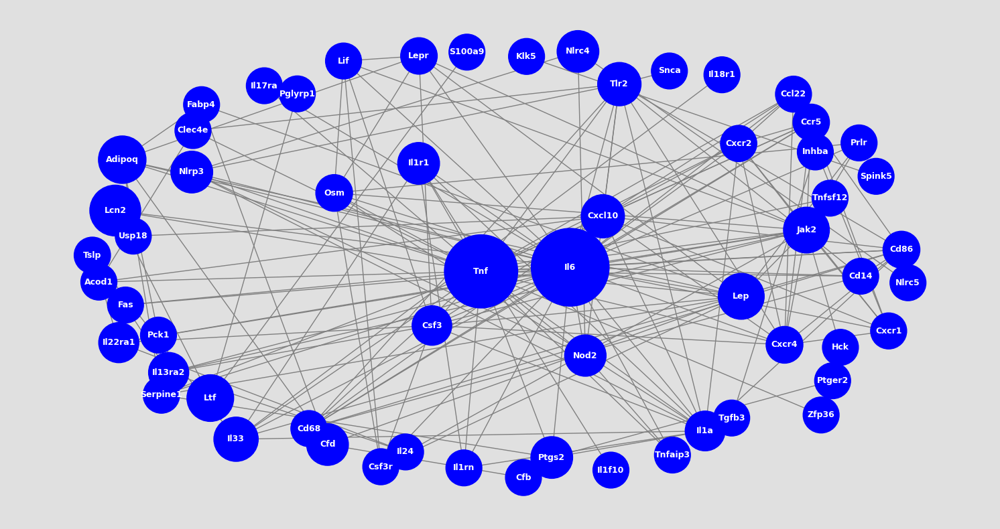

In [16]:
# Initialize mygene
mg = mygene.MyGeneInfo()

def gene_gene_names(gene_ids):
    # Query mygene to get gene symbols
    result = mg.querymany(gene_ids, scopes='entrezgene', fields='symbol', species='mouse')
    # Extract gene symbols from the result
    gene_symbols = {entry['query']: entry['symbol'] for entry in result if 'symbol' in entry}

    # Display the gene symbols
    protein_list = [gene for gene in gene_symbols.values()]
    return protein_list

# Checking interaction between Acod1, HIF1, NFKb, Succinate dehydrogenases, pro-inflammatory
# TODO

# List of gene IDs from cytokind cytokine receptor interaction
cytokines = ["20299","12774","56708","12985","12986","15945","227288","12765","12767","14102","16165","16172","16182","16175","215274","16177","16181","230828","93672","77125","16193","16323","16846","16847","16878","18413","19116","21809","21926","94185","21944","53603"]
cytokines = gene_gene_names(cytokines)
# List of gene ids from jak-stat signaling
#jak_stat = ["12048","56708","12803","57914","12981","12985","12986","13645","14199","14784","15976","15979","15980","16156","16160","16165","329244","60504","230828","237310","209590","93672","16184","16186","16188","16192","16193","16452","16453","16846","16847","16878","17210","18413","18712","19116","19255","110157","12703","12702","20849","53603"]
#jak_stat = gene_gene_names(jak_stat)

# Top 2 BP associated genes
immune_defense = ["Abcd2","Acod1","Adamts4","Adamts9","Adipoq","Bcl3","Bdkrb1","Cd14","Cd68","Cd86","Cfb","Cfd","Clec4e","Cnr2","Cxcl10","Dmbt1","Fabp4","Tent5a","Cyrib","Gch1","Hck","Il1a","Il1f10","Il22ra1","Il6","Jak2","Jchain","Klk5","Lcn2","Litaf","Lrg1","Ltf","Ly6g6c","Macrod2","Nlrc4","Nlrc5","Nlrp3","Nod2","Nos3","Nr1d1","Pck1","Pde2a","Pde4b","Pglyrp1","Plac8","Plscr1","Ppl","Prlr","Ptafr","Ptger2","Ptgs2","Rgs1","Rnase4","S100a9","Sbno2","Serpine1","Slc11a1","Snca","Spink5","Tlr2","Tnf","Tnfaip3","Tnnt2","Trib1","Tslp","Usp18","Vgf","Wfdc2","Wfdc3","Zfp36"]

highlighted_genes = [] #["Acod1", "Hif1a", "Nfe2l2", "Keap1", "Egln1", "Egln2", "Egln3", "ATF3", "Nfkb1", "Rela"]


protein_list = cytokines  + immune_defense # + jak_stat
print(protein_list)

proteins = '%0d'.join(protein_list)
url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
r = requests.get(url)

lines = r.text.split('\n') # pull the text from the response object and split based on new lines
data = [l.split('\t') for l in lines] # split each line into its components based on tabs
# convert to dataframe using the first row as the column names; drop empty, final row
df = pd.DataFrame(data[1:-1], columns = data[0]) 
# dataframe with the preferred names of the two proteins and the score of the interaction
interactions = df[['preferredName_A', 'preferredName_B', 'score']]  
display(interactions.head(10))
interactions['score'] = pd.to_numeric(interactions['score'])
interactions = interactions[interactions['score'] > 0.70]


G=nx.Graph(name='Protein Interaction Graph')
interactions = np.array(interactions)
for i in range(len(interactions)):
    interaction = interactions[i]
    a = interaction[0] # protein a node
    b = interaction[1] # protein b node
    w = float(interaction[2]) # score as weighted edge where high scores = low weight
    G.add_weighted_edges_from([(a,b,w)]) # add weighted edge to graph
    
pos = nx.spring_layout(G) # position the nodes using the spring layout
plt.figure(figsize=(11,11),facecolor=[0.7,0.7,0.7,0.4])
#nx.draw_networkx(G, node_size=500, node_color="skyblue")
#plt.axis('off')
#plt.show()

# function to rescale list of values to range [newmin,newmax]
def rescale(l,newmin,newmax):
    arr = list(l)
    return [(x-min(arr))/(max(arr)-min(arr))*(newmax-newmin)+newmin for x in arr]

# use the matplotlib viridis colormap
graph_colormap = cm.get_cmap('viridis', 12)

# node color varies with Degree
c = rescale([G.degree(v) for v in G],0.0,0.9) 
c = [graph_colormap(i) for i in c]

# node size varies with betweeness centrality - map to range [10,100] 
bc = nx.betweenness_centrality(G) # betweeness centrality
s =  rescale([v for v in bc.values()],1500,7000)

# edge width shows 1-weight to convert cost back to strength of interaction 
ew = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,4)

# edge color also shows weight
ec = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,1)
ec = [graph_colormap(i) for i in ec]
# Edge color set to grey
ec = ['grey' for _ in G.edges]

pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
plt.figure(figsize=(19, 10),facecolor=[0.7,0.7,0.7,0.4])
#nx.draw_networkx(G, pos=pos, with_labels=True, node_color=c, node_size=s, edge_color=ec, width=ew,
#                 font_color='white', font_weight='bold', font_size='9')
# Assigning colors to nodes
node_color = []
for node in G.nodes():
    if node in highlighted_genes:
        node_color.append('red')
    else:
        node_color.append('blue')
nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color = node_color, 
                 font_color='white', font_weight='bold', font_size='9', edge_color = ec)
# Save the graph in GraphML format for Cytoscape
nx.write_graphml(G, "protein_interaction_graph.graphml")
plt.axis('off')
plt.show()

In [11]:
Analyze the above network using
1) https://genemania.org/
2) https://metascape.org/gp/index.html#/main/step1
3) https://maayanlab.cloud/chea3/#top
4) https://maayanlab.cloud/Enrichr/
5) Master regulator - https://www.grnpedia.org/trrust/key_regulator/6a41cee46a.php
6) Master regulator - Use the top genes from the top pathway in BP, and KEGG to find master regulators - https://metascape.org/gp/index.html#/main/step1

SyntaxError: invalid syntax (1885113727.py, line 1)

In [ ]:
len(['Ccl17', 'Ccl22', 'Ccl24', 'Ccl5', 'Ccr1', 'Ccr5', 'Clcf1', 'Cntf', 'Crlf2', 'Csf2', 'Csf3', 'Csf3r', 'Cxcl10', 'Cxcr1', 'Cxcr2', 'Cxcr4', 'Fas', 'Gdf15', 'Gdf5', 'Ifnar2', 'Ifngr1', 'Ifngr2', 'Il11', 'Il12b', 'Il13ra2', 'Il17ra', 'Il18r1', 'Il18rap', 'Il19', 'Il1a', 'Il1b', 'Il1f10', 'Il1r1', 'Il1r2', 'Il1rap', 'Il1rn', 'Il21r', 'Il22ra1', 'Il23r', 'Il24', 'Il2ra', 'Il2rg', 'Il33', 'Il3ra', 'Il5ra', 'Il6', 'Inhba', 'Lep', 'Lepr', 'Lif', 'Ltb', 'Mstn', 'Osm', 'Ppbp', 'Prlr', 'Tnf', 'Tnfrsf14', 'Tnfrsf1b', 'Tnfsf14', 'Tnfsf18', 'Tnfsf8', 'Tslp', 'Bcl2l1', 'Clcf1', 'Cntf', 'Crlf2', 'Csf2', 'Csf3', 'Csf3r', 'Egf', 'Fhl1', 'Grb2', 'Ifnar2', 'Ifngr1', 'Ifngr2', 'Il11', 'Il12b', 'Il13ra2', 'Il19', 'Il21r', 'Il22ra1', 'Il22ra2', 'Il23r', 'Il24', 'Il2ra', 'Il2rg', 'Il3ra', 'Il5ra', 'Il6', 'Jak2', 'Jak3', 'Lep', 'Lepr', 'Lif', 'Mcl1', 'Osm', 'Pim1', 'Prlr', 'Ptpn2', 'Raf1', 'Socs1', 'Socs3', 'Stat4', 'Tslp', 'Acod1', 'Adora2b', 'Anxa1', 'Anxa3', 'Apbb1ip', 'Arg1', 'Arid5a', 'Arrb2', 'B2m', 'Batf', 'Bcl10', 'Bcl3', 'Btk', 'Casp1', 'Casp4', 'Cd177', 'Cd37', 'Cd46', 'Cd55', 'Cd86', 'Cebpb', 'Cfh', 'Clcf1', 'Clec4d', 'Clec4e', 'Clec4g', 'Coro1a', 'Crlf2', 'Ctsh', 'Dock2', 'Cyrib', 'Fas', 'Fcer1g', 'Fes', 'Fgr', 'Fut7', 'Gadd45g', 'Gapt', 'Grp', 'Hlx', 'Hmox1', 'Icam1', 'Il12b', 'Il13ra2', 'Il18r1', 'Il18rap', 'Il1b', 'Il1r1', 'Il21r', 'Il23r', 'Il33', 'Il6', 'Inpp5d', 'Irak3', 'Irf1', 'Itgal', 'Itgam', 'Itgb2', 'Ivl', 'Jak3', 'Klk5', 'Klk7', 'Laptm5', 'Lat2', 'Lcp1', 'Lep', 'Litaf', 'Lyn', 'Cgas', 'Myo1f', 'Nckap1l', 'Nfkbid', 'Nfkbiz', 'Nkg7', 'Nlrp3', 'Nmi', 'Nod2', 'Nr4a3', 'Pck1', 'Pglyrp1', 'Pla2g5', 'Pnp', 'Ppl', 'Pram1', 'Prf1', 'Ptafr', 'Ptgds', 'Ptk2b', 'Ptpn22', 'Ptprc', 'Ptprj', 'Ptx3', 'Rab27a', 'Rab44', 'Rac2', 'Rara', 'Relb', 'Ripk2', 'Rnf19b', 'Rsad2', 'Sash3', 'Sbno2', 'Slamf1', 'Slc11a1', 'Spi1', 'Spink5', 'Stx11', 'Stx7', 'Sucnr1', 'Syk', 'Tcirg1', 'Tlr2', 'Tlr4', 'Tlr7', 'Tnf', 'Tnfaip3', 'Tnfrsf14', 'Tnfrsf1b', 'Tnfsf18', 'Treml4', 'Tyrobp', 'Vav1', 'Zbtb1', 'Zc3h12a'])

In [19]:
def intersection(lst1, lst2):
    lst3 = [value for value in lst1 if value in lst2]
    return lst3

len(intersection(immune_defense, jak_stat))

9

In [20]:
len(['Ccl17', 'Ccl22', 'Ccl24', 'Ccl5', 'Ccr1', 'Ccr5', 'Clcf1', 'Cntf', 'Crlf2', 'Csf2', 'Csf3', 'Csf3r', 'Cxcl10', 'Cxcr1', 'Cxcr2', 'Cxcr4', 'Fas', 'Gdf15', 'Gdf5', 'Ifnar2', 'Ifngr1', 'Ifngr2', 'Il11', 'Il12b', 'Il13ra2', 'Il17ra', 'Il18r1', 'Il18rap', 'Il19', 'Il1a', 'Il1b', 'Il1f10', 'Il1r1', 'Il1r2', 'Il1rap', 'Il1rn', 'Il21r', 'Il22ra1', 'Il23r', 'Il24', 'Il2ra', 'Il2rg', 'Il33', 'Il3ra', 'Il5ra', 'Il6', 'Inhba', 'Lep', 'Lepr', 'Lif', 'Ltb', 'Mstn', 'Osm', 'Ppbp', 'Prlr', 'Tnf', 'Tnfrsf14', 'Tnfrsf1b', 'Tnfsf14', 'Tnfsf18', 'Tnfsf8', 'Tslp', 'Bcl2l1', 'Clcf1', 'Cntf', 'Crlf2', 'Csf2', 'Csf3', 'Csf3r', 'Egf', 'Fhl1', 'Grb2', 'Ifnar2', 'Ifngr1', 'Ifngr2', 'Il11', 'Il12b', 'Il13ra2', 'Il19', 'Il21r', 'Il22ra1', 'Il22ra2', 'Il23r', 'Il24', 'Il2ra', 'Il2rg', 'Il3ra', 'Il5ra', 'Il6', 'Jak2', 'Jak3', 'Lep', 'Lepr', 'Lif', 'Mcl1', 'Osm', 'Pim1', 'Prlr', 'Ptpn2', 'Raf1', 'Socs1', 'Socs3', 'Stat4', 'Tslp', 'Acod1', 'Adora2b', 'Anxa1', 'Anxa3', 'Apbb1ip', 'Arg1', 'Arid5a', 'Arrb2', 'B2m', 'Batf', 'Bcl10', 'Bcl3', 'Btk', 'Casp1', 'Casp4', 'Cd177', 'Cd37', 'Cd46', 'Cd55', 'Cd86', 'Cebpb', 'Cfh', 'Clcf1', 'Clec4d', 'Clec4e', 'Clec4g', 'Coro1a', 'Crlf2', 'Ctsh', 'Dock2', 'Cyrib', 'Fas', 'Fcer1g', 'Fes', 'Fgr', 'Fut7', 'Gadd45g', 'Gapt', 'Grp', 'Hlx', 'Hmox1', 'Icam1', 'Il12b', 'Il13ra2', 'Il18r1', 'Il18rap', 'Il1b', 'Il1r1', 'Il21r', 'Il23r', 'Il33', 'Il6', 'Inpp5d', 'Irak3', 'Irf1', 'Itgal', 'Itgam', 'Itgb2', 'Ivl', 'Jak3', 'Klk5', 'Klk7', 'Laptm5', 'Lat2', 'Lcp1', 'Lep', 'Litaf', 'Lyn', 'Cgas', 'Myo1f', 'Nckap1l', 'Nfkbid', 'Nfkbiz', 'Nkg7', 'Nlrp3', 'Nmi', 'Nod2', 'Nr4a3', 'Pck1', 'Pglyrp1', 'Pla2g5', 'Pnp', 'Ppl', 'Pram1', 'Prf1', 'Ptafr', 'Ptgds', 'Ptk2b', 'Ptpn22', 'Ptprc', 'Ptprj', 'Ptx3', 'Rab27a', 'Rab44', 'Rac2', 'Rara', 'Relb', 'Ripk2', 'Rnf19b', 'Rsad2', 'Sash3', 'Sbno2', 'Slamf1', 'Slc11a1', 'Spi1', 'Spink5', 'Stx11', 'Stx7', 'Sucnr1', 'Syk', 'Tcirg1', 'Tlr2', 'Tlr4', 'Tlr7', 'Tnf', 'Tnfaip3', 'Tnfrsf14', 'Tnfrsf1b', 'Tnfsf18', 'Treml4', 'Tyrobp', 'Vav1', 'Zbtb1', 'Zc3h12a'])

228

# Plot immuno-metabolic-hypoxic genes

# Scatter plot of gene correlation intensity change across stages and species

,gene,Spalax Wound,Mouse Wound
0,Fgf23,10.474362,5.918510
1,Csf3,10.224749,3.220491
2,Mmp8,9.817702,3.243524
3,Il6,8.902967,2.826244
4,Pglyrp1,8.847524,6.678304
5,Acod1,8.623965,7.468665
6,Lcn2,8.621951,3.386748
7,Osm,7.976595,7.324645
8,Mmp9,7.682893,5.682691
9,Treml2,7.668161,4.211599


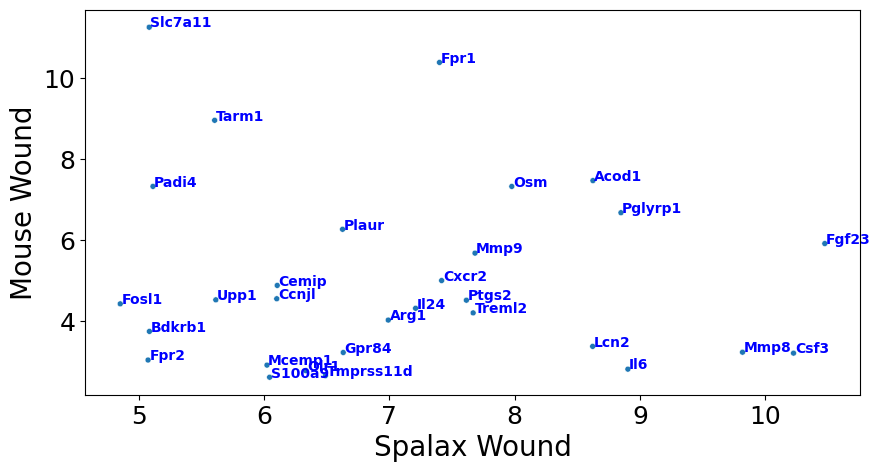

    Spalax Wound  Mouse Wound
0      10.474362     5.918510
1      10.224749     3.220491
2       9.817702     3.243524
3       8.902967     2.826244
4       8.847524     6.678304
5       8.623965     7.468665
6       8.621951     3.386748
7       7.976595     7.324645
8       7.682893     5.682691
9       7.668161     4.211599
10      7.614333     4.523753
11      7.416637     5.007783
12      7.399615    10.377652
13      7.208782     4.324972
14      6.990966     4.034753
15      6.631397     3.236191
16      6.625973     6.269829
17      6.489205     2.665776
18      6.332963     2.789373
19      6.104609     4.887599
20      6.100801     4.559667
21      6.043920     2.627540
22      6.022853     2.925874
23      5.614485     4.532936
24      5.605331     8.952987
25      5.112980     7.325260
26      5.084748     3.755608
27      5.083288    11.244457
28      5.073906     3.050944
29      4.852054     4.434419


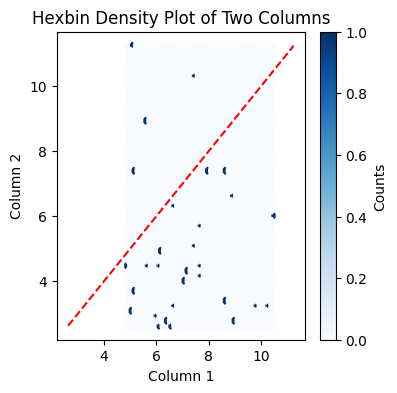

,gene,Spalax Wound,Spalax Scab
0,Fgf23,10.474362,3.563908
1,Pglyrp1,8.847524,5.879556
2,Acod1,8.623965,4.825366
3,Lcn2,8.621951,3.161798
4,Slc11a1,8.189936,4.275902
5,Osm,7.976595,3.278837
6,Wnt7a,7.743508,3.247401
7,Mmp9,7.682893,4.848951
8,Treml2,7.668161,5.338967
9,Ptgs2,7.614333,3.288140


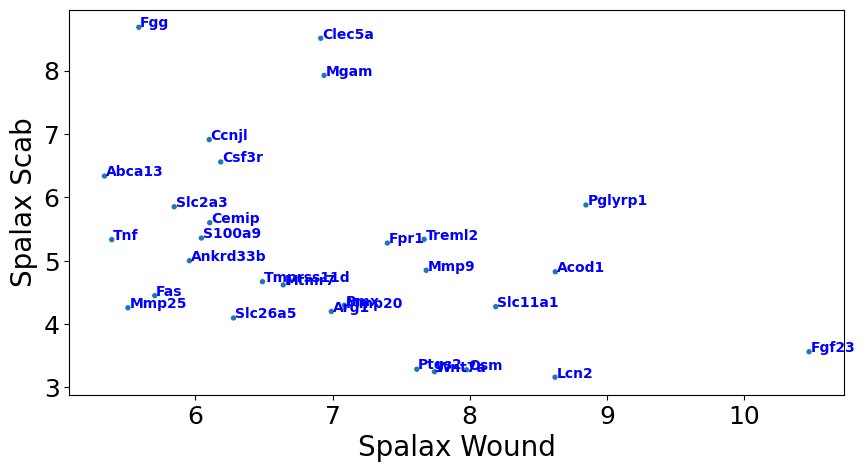

    Spalax Wound  Spalax Scab
0      10.474362     3.563908
1       8.847524     5.879556
2       8.623965     4.825366
3       8.621951     3.161798
4       8.189936     4.275902
5       7.976595     3.278837
6       7.743508     3.247401
7       7.682893     4.848951
8       7.668161     5.338967
9       7.614333     3.288140
10      7.399615     5.279370
11      7.086363     4.258706
12      7.085978     4.297521
13      6.990966     4.199467
14      6.938106     7.924422
15      6.913837     8.510684
16      6.640289     4.618032
17      6.489205     4.669546
18      6.277954     4.096666
19      6.184737     6.558919
20      6.104609     5.600336
21      6.100801     6.911721
22      6.043920     5.357905
23      5.956551     5.000277
24      5.845712     5.851764
25      5.703539     4.448983
26      5.587538     8.684994
27      5.508126     4.257827
28      5.390225     5.333183
29      5.337313     6.336625


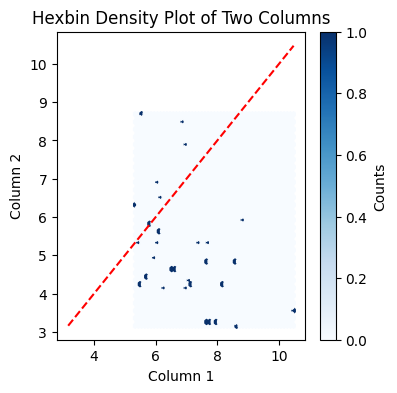

In [7]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/genesymbol/"
os.chdir(path)

import pandas as pd

def get_antilog(df_fold_change):
    df_fold_change.rename(columns={df_fold_change.columns[0]: "GeneSymbol", 
                                   df_fold_change.columns[1]: "GeneID"}, inplace=True)
    log2_fold_changes = df_fold_change['log2FoldChange']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes   
    df_fold_change = df_fold_change.rename(columns = {'log2FoldChange': 'logFC'})
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'logFC', 'Antilog_FC', 'padj']]  # 'logCPM', 
    return df_fold_change

def make_df_similar_genes(df1, df2, gene_column, top_n=30):    
    df1_genes = list(df1[gene_column])
    df2_genes = list(df2[gene_column])
    intersection = list(set(df1_genes) & set(df2_genes))
    df1 = df1[df1[gene_column].isin(intersection)] 
    df2 = df2[df2[gene_column].isin(intersection)]
    
    df1_sorted = df1.sort_values(by='Antilog_FC', ascending=False).reset_index(drop=True)
    top_df1 = df1_sorted.head(top_n)
    
    top_df2= df2[df2[gene_column].isin(top_df1.GeneSymbol)]
    
    # Select top_n genes from each sorted DataFrame
    
    return top_df1, top_df2


def plot_similar_genes(sample1, sample2, label1, label2):
    # Simulate some data
    np.random.seed(0)
    df_1, df_2 = make_df_similar_genes(sample1, sample2, 'GeneSymbol')
    df_dmba = pd.DataFrame({
        'gene': df_1.GeneSymbol, 
        label1: df_1['logFC'].values,
        label2: df_2['logFC'].values
    })

    display(df_dmba.head(30))

    # Create scatter plot
    plt.figure(figsize=(10,5))
    p1 = sns.scatterplot(
        x=label1, 
        y=label2, 
        data=df_dmba, 
        size=8,
        legend=False
    )

    # Annotate each dot with the species name using iterrows
    for index, row in df_dmba.iterrows():
        p1.text(
            row[label1] + 0.01, 
            row[label2], 
            row['gene'], 
            horizontalalignment='left', 
            size=10, 
            color='blue', 
            weight='semibold'
        )

    plt.xlabel(label1, fontsize = 20)
    plt.ylabel(label2, fontsize = 20)
    plt.xticks(fontsize=18)
    plt.yticks(fontsize=18)
    #plt.savefig('upregulated_downregulated.jpg', format='jpeg', dpi=300, bbox_inches='tight')
    plt.show()
    
    # Hexbin plot example
    print(df_dmba.iloc[:, 1:3])
    plt.figure(figsize=(4,4 ))
    hb = plt.hexbin(df_dmba[label1], df_dmba[label2], gridsize=50, cmap='Blues')
    cb = plt.colorbar(hb, label='Counts')
    plt.plot([df_dmba.iloc[:, 1:3].min().min(), df_dmba.iloc[:, 1:3].max().max()], [df_dmba.iloc[:, 1:3].min().min(), df_dmba.iloc[:, 1:3].max().max()], 'r--')  # Line of equality
    plt.title('Hexbin Density Plot of Two Columns')
    plt.xlabel('Column 1')
    plt.ylabel('Column 2')
    plt.show()    
    
spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)

mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv") 
mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)

spalax_scar_foldchange = pd.read_csv("S.control-S.scar/S.control-S.scar_genes.csv") 
spalax_scar_foldchange = spalax_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_scar_foldchange = get_antilog(spalax_scar_foldchange)

mouse_scar_foldchange = pd.read_csv("MM.control-M.scar/MM.control-M.scar_genes.csv") 
mouse_scar_foldchange = mouse_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_scar_foldchange = get_antilog(mouse_scar_foldchange)
   
    
plot_similar_genes(spalax_wound_foldchange, mouse_wound_foldchange, 'Spalax Wound', 'Mouse Wound')
plot_similar_genes(spalax_wound_foldchange, spalax_scar_foldchange, 'Spalax Wound', 'Spalax Scab')

,gene,Spalax wound,mouse wound
0,Fgf23,10.474362,5.918510
1,Csf3,10.224749,3.220491
2,Mmp8,9.817702,3.243524
3,Il6,8.902967,2.826244
4,Pglyrp1,8.847524,6.678304
5,Acod1,8.623965,7.468665
6,Lcn2,8.621951,3.386748
7,Osm,7.976595,7.324645
8,Mmp9,7.682893,5.682691
9,Treml2,7.668161,4.211599


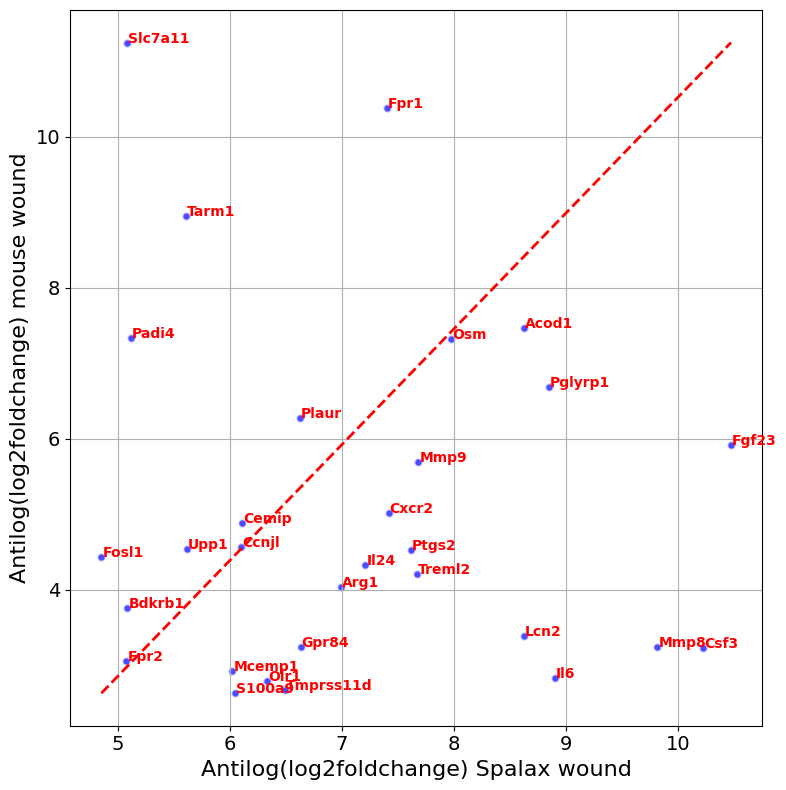

,gene,Spalax wound,Spalax scab
0,Fgf23,10.474362,3.563908
1,Pglyrp1,8.847524,5.879556
2,Acod1,8.623965,4.825366
3,Lcn2,8.621951,3.161798
4,Slc11a1,8.189936,4.275902
5,Osm,7.976595,3.278837
6,Wnt7a,7.743508,3.247401
7,Mmp9,7.682893,4.848951
8,Treml2,7.668161,5.338967
9,Ptgs2,7.614333,3.288140


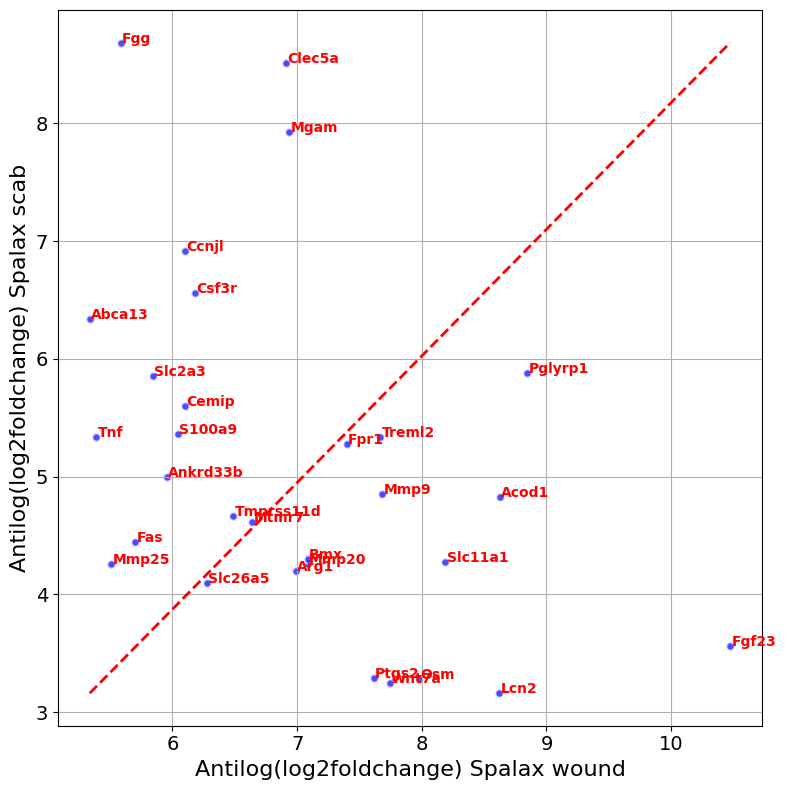

In [10]:
def get_antilog(df_fold_change):
    df_fold_change.rename(columns={df_fold_change.columns[0]: "GeneSymbol", 
                                   df_fold_change.columns[1]: "GeneID"}, inplace=True)
    log2_fold_changes = df_fold_change['log2FoldChange']
    antilog_fold_changes = np.power(2, log2_fold_changes)
    df_fold_change['Antilog_FC'] = antilog_fold_changes   
    df_fold_change = df_fold_change.rename(columns = {'log2FoldChange': 'logFC'})
    df_fold_change = df_fold_change[['GeneSymbol', 'GeneID', 'logFC', 'Antilog_FC', 'padj']]  # 'logCPM', 
    return df_fold_change

def make_df_similar_genes(df1, df2, gene_column, top_n=30):    
    df1_genes = list(df1[gene_column])
    df2_genes = list(df2[gene_column])
    intersection = list(set(df1_genes) & set(df2_genes))
    df1 = df1[df1[gene_column].isin(intersection)] 
    df2 = df2[df2[gene_column].isin(intersection)]
    
    df1_sorted = df1.sort_values(by='Antilog_FC', ascending=False).reset_index(drop=True)
    top_df1 = df1_sorted.head(top_n)
    
    top_df2= df2[df2[gene_column].isin(top_df1.GeneSymbol)]
    
    # Select top_n genes from each sorted DataFrame
    
    return top_df1, top_df2


def plot_similar_genes(sample1, sample2, label1, label2):
    # Simulate some data
    np.random.seed(0)
    df_1, df_2 = make_df_similar_genes(sample1, sample2, 'GeneSymbol')
    df_dmba = pd.DataFrame({
        'gene': df_1.GeneSymbol, 
        label1: df_1['logFC'].values,
        label2: df_2['logFC'].values
    })
    display(df_dmba.head(30))
    
    # Create scatter plot
    plt.figure(figsize=(8, 8))  # Adjust figure size as needed
    plt.scatter(
        df_dmba[label1], 
        df_dmba[label2], 
        c='blue',  # Single color for all points
        alpha=0.7,  # Transparency
        edgecolors='w',  # White edge around markers
        linewidth=1.5  # Line width of marker edges
    )

    # Annotate each dot with the gene name
    for i, txt in enumerate(df_dmba['gene']):
        plt.text(
            df_dmba[label1][i] + 0.01,  # Adjust text position slightly to the right
            df_dmba[label2][i], 
            txt, 
            horizontalalignment='left', 
            size=10, 
            color='red', 
            weight='semibold'
        )

    plt.xlabel('Antilog(log2foldchange)' + ' '+ label1, fontsize=16)
    plt.ylabel('Antilog(log2foldchange)'+ ' '+ label2, fontsize=16)
    plt.xticks(fontsize=14)
    plt.yticks(fontsize=14)
    
    # Plot the line of equality (y = x)
    plt.plot([df_dmba[label1].min(), df_dmba[label1].max()], 
             [df_dmba[label2].min(), df_dmba[label2].max()], 
             'r--', linewidth=2)

    plt.grid(True)
    plt.tight_layout()

    plt.show()         
    
spalax_wound_foldchange = pd.read_csv("S.control-S.wound/S.control-S.wound_genes.csv") 
spalax_wound_foldchange = spalax_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_wound_foldchange = get_antilog(spalax_wound_foldchange)

mouse_wound_foldchange = pd.read_csv("MM.control-M.wound/MM.control-M.wound_genes.csv") 
mouse_wound_foldchange = mouse_wound_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_wound_foldchange = get_antilog(mouse_wound_foldchange)

spalax_scar_foldchange = pd.read_csv("S.control-S.scar/S.control-S.scar_genes.csv") 
spalax_scar_foldchange = spalax_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
spalax_scar_foldchange = get_antilog(spalax_scar_foldchange)

mouse_scar_foldchange = pd.read_csv("MM.control-M.scar/MM.control-M.scar_genes.csv") 
mouse_scar_foldchange = mouse_scar_foldchange.rename(columns = {'Unnamed: 0': 'GeneID'})
mouse_scar_foldchange = get_antilog(mouse_scar_foldchange)
   
    
plot_similar_genes(spalax_wound_foldchange, mouse_wound_foldchange, 'Spalax wound', 'mouse wound')
plot_similar_genes(spalax_wound_foldchange, spalax_scar_foldchange, 'Spalax wound', 'Spalax scab')

### Bar plots for future use

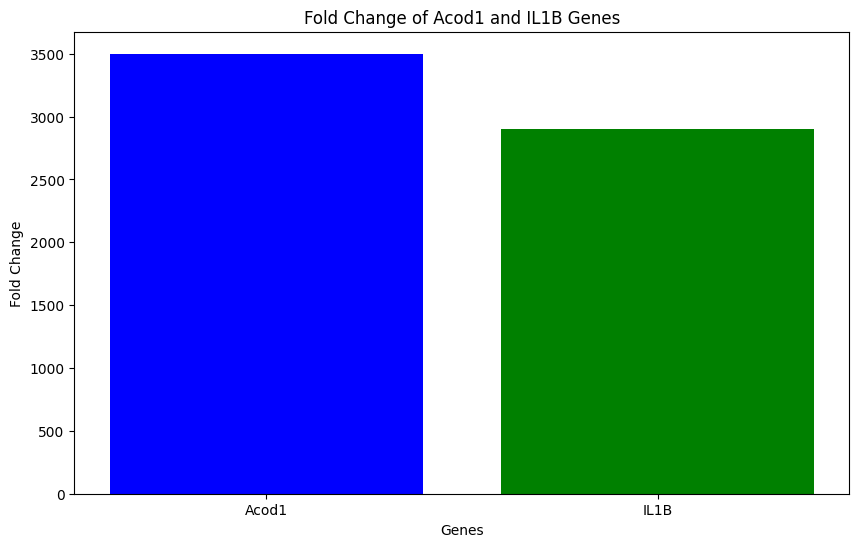

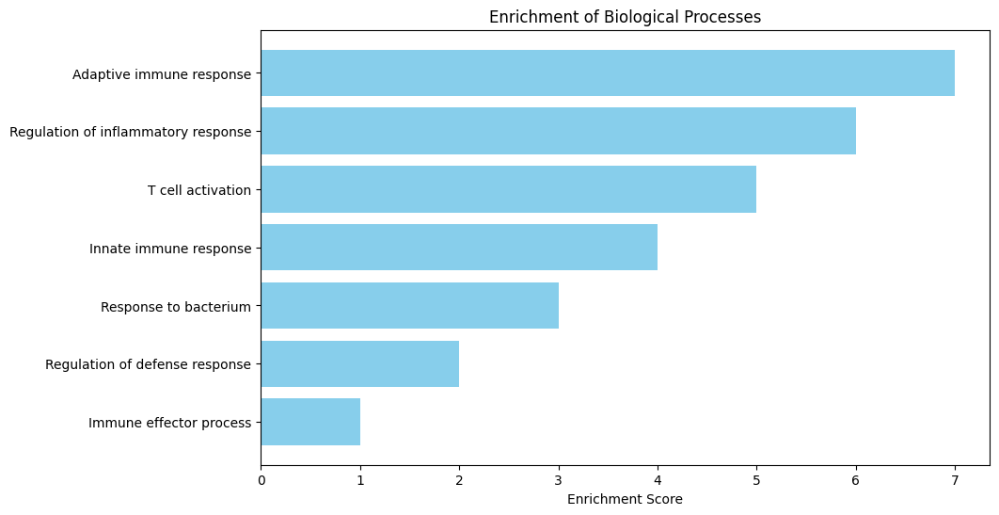

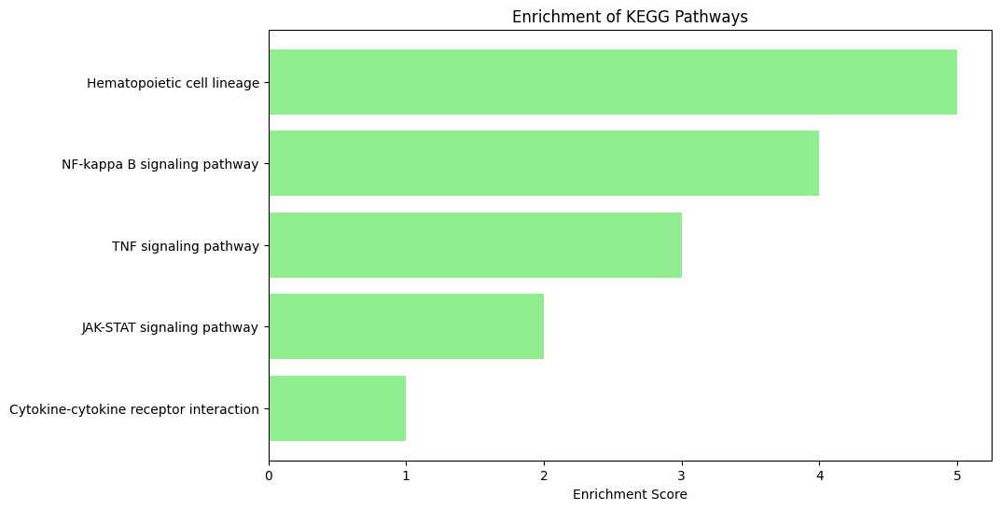

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Data for the figures
genes = ['Acod1', 'IL1B']
fold_changes = [3500, 2900]
biological_processes = ['Immune effector process', 'Regulation of defense response', 'Response to bacterium',
                        'Innate immune response', 'T cell activation', 'Regulation of inflammatory response', 
                        'Adaptive immune response']
kegg_pathways = ['Cytokine-cytokine receptor interaction', 'JAK-STAT signaling pathway', 
                 'TNF signaling pathway', 'NF-kappa B signaling pathway', 'Hematopoietic cell lineage']

# Figure for fold changes of Acod1 and IL1B genes
plt.figure(figsize=(10, 6))
plt.bar(genes, fold_changes, color=['blue', 'green'])
plt.xlabel('Genes')
plt.ylabel('Fold Change')
plt.title('Fold Change of Acod1 and IL1B Genes')
#plt.savefig('/mnt/data/gene_fold_changes.png')
plt.show()

# Figure for enrichment of biological processes
plt.figure(figsize=(10, 6))
y_pos = np.arange(len(biological_processes))
plt.barh(y_pos, np.arange(1, len(biological_processes)+1), align='center', color='skyblue')
plt.yticks(y_pos, biological_processes)
plt.xlabel('Enrichment Score')
plt.title('Enrichment of Biological Processes')
#plt.savefig('/mnt/data/biological_processes_enrichment.png')
plt.show()

# Figure for enrichment of KEGG pathways
plt.figure(figsize=(10, 6))
y_pos = np.arange(len(kegg_pathways))
plt.barh(y_pos, np.arange(1, len(kegg_pathways)+1), align='center', color='lightgreen')
plt.yticks(y_pos, kegg_pathways)
plt.xlabel('Enrichment Score')
plt.title('Enrichment of KEGG Pathways')
#plt.savefig('/mnt/data/kegg_pathways_enrichment.png')
plt.show()

## Functions

In [15]:
def plot_network(protein_list):
    highlighted_genes = ["Acod1"]
    protein_list = protein_list + highlighted_genes
    print(protein_list)

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n') # pull the text from the response object and split based on new lines
    data = [l.split('\t') for l in lines] # split each line into its components based on tabs
    # convert to dataframe using the first row as the column names; drop empty, final row
    df = pd.DataFrame(data[1:-1], columns = data[0]) 
    # dataframe with the preferred names of the two proteins and the score of the interaction
    interactions = df[['preferredName_A', 'preferredName_B', 'score']]  


    G=nx.Graph(name='Protein Interaction Graph')
    interactions = np.array(interactions)
    for i in range(len(interactions)):
        interaction = interactions[i]
        a = interaction[0] # protein a node
        b = interaction[1] # protein b node
        w = float(interaction[2]) # score as weighted edge where high scores = low weight
        G.add_weighted_edges_from([(a,b,w)]) # add weighted edge to graph

    pos = nx.spring_layout(G) # position the nodes using the spring layout
    plt.figure(figsize=(11,11),facecolor=[0.7,0.7,0.7,0.4])
    #nx.draw_networkx(G, node_size=500, node_color="skyblue")
    #plt.axis('off')
    #plt.show()

    # function to rescale list of values to range [newmin,newmax]
    def rescale(l,newmin,newmax):
        arr = list(l)
        return [(x-min(arr))/(max(arr)-min(arr))*(newmax-newmin)+newmin for x in arr]

    # use the matplotlib viridis colormap
    graph_colormap = cm.get_cmap('viridis', 12)

    # node color varies with Degree
    c = rescale([G.degree(v) for v in G],0.0,0.9) 
    c = [graph_colormap(i) for i in c]

    # node size varies with betweeness centrality - map to range [10,100] 
    bc = nx.betweenness_centrality(G) # betweeness centrality
    s =  rescale([v for v in bc.values()],1500,7000)

    # edge width shows 1-weight to convert cost back to strength of interaction 
    ew = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,4)

    # edge color also shows weight
    ec = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,1)
    ec = [graph_colormap(i) for i in ec]

    pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
    plt.figure(figsize=(19, 10),facecolor=[0.7,0.7,0.7,0.4])
    #nx.draw_networkx(G, pos=pos, with_labels=True, node_color=c, node_size=s, edge_color=ec, width=ew,
    #                 font_color='white', font_weight='bold', font_size='9')
    # Assigning colors to nodes
    node_color = []
    for node in G.nodes():
        if node in highlighted_genes:
            node_color.append('red')
        else:
            node_color.append('blue')
    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color = node_color, 
                     font_color='white', font_weight='bold', font_size='9')
    plt.axis('off')
    plt.show()
    

def plot_network_with_weights(protein_list):
    highlighted_genes = ["Acod1"]
    protein_list = protein_list + highlighted_genes
    print(protein_list)

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n') # pull the text from the response object and split based on new lines
    data = [l.split('\t') for l in lines] # split each line into its components based on tabs
    # convert to dataframe using the first row as the column names; drop empty, final row
    df = pd.DataFrame(data[1:-1], columns = data[0]) 
    # dataframe with the preferred names of the two proteins and the score of the interaction
    interactions = df[['preferredName_A', 'preferredName_B', 'score']]  


    G=nx.Graph(name='Protein Interaction Graph')
    interactions = np.array(interactions)
    for i in range(len(interactions)):
        interaction = interactions[i]
        a = interaction[0] # protein a node
        b = interaction[1] # protein b node
        w = float(interaction[2]) # score as weighted edge where high scores = low weight
        G.add_weighted_edges_from([(a,b,w)]) # add weighted edge to graph

    pos = nx.spring_layout(G) # position the nodes using the spring layout
    plt.figure(figsize=(11,11),facecolor=[0.7,0.7,0.7,0.4])
    #nx.draw_networkx(G, node_size=500, node_color="skyblue")
    #plt.axis('off')
    #plt.show()

    # function to rescale list of values to range [newmin,newmax]
    def rescale(l,newmin,newmax):
        arr = list(l)
        return [(x-min(arr))/(max(arr)-min(arr))*(newmax-newmin)+newmin for x in arr]

    # use the matplotlib viridis colormap
    graph_colormap = cm.get_cmap('viridis', 12)

    # node color varies with Degree
    c = rescale([G.degree(v) for v in G],0.0,0.9) 
    c = [graph_colormap(i) for i in c]

    # node size varies with betweeness centrality - map to range [10,100] 
    bc = nx.betweenness_centrality(G) # betweeness centrality
    s =  rescale([v for v in bc.values()],1500,7000)

    # edge width shows 1-weight to convert cost back to strength of interaction 
    ew = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,4)

    # edge color also shows weight
    ec = rescale([float(G[u][v]['weight']) for u,v in G.edges],0.1,1)
    ec = [graph_colormap(i) for i in ec]

    pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
    plt.figure(figsize=(19, 10),facecolor=[0.7,0.7,0.7,0.4])
    #nx.draw_networkx(G, pos=pos, with_labels=True, node_color=c, node_size=s, edge_color=ec, width=ew,
    #                 font_color='white', font_weight='bold', font_size='9')
    # Assigning colors to nodes
    node_color = []
    for node in G.nodes():
        if node in highlighted_genes:
            node_color.append('red')
        else:
            node_color.append('blue')
            
    # Assigning colors to edges
    edge_color = []
    for u, v in G.edges():
        if u in highlighted_genes or v in highlighted_genes:
            edge_color.append('red')
        else:
            edge_color.append(graph_colormap(rescale([float(G[u][v]['weight'])], 0.1, 1)[0]))
            
    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color = node_color, 
                     font_color='white', font_weight='bold', font_size='9')
    plt.axis('off')
    plt.show()
    

def plot_network(protein_list):
    highlighted_genes = ["Acod1"]
    protein_list = protein_list + highlighted_genes
    print(protein_list)

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n')  # pull the text from the response object and split based on new lines
    data = [l.split('\t') for l in lines]  # split each line into its components based on tabs
    # convert to dataframe using the first row as the column names; drop empty, final row
    df = pd.DataFrame(data[1:-1], columns=data[0]) 
    # dataframe with the preferred names of the two proteins and the score of the interaction
    interactions = df[['preferredName_A', 'preferredName_B']]  

    G = nx.Graph(name='Protein Interaction Graph')
    interactions = np.array(interactions)
    for i in range(len(interactions)):
        interaction = interactions[i]
        a = interaction[0]  # protein a node
        b = interaction[1]  # protein b node
        G.add_edge(a, b)  # add edge to graph without weight

    pos = nx.spring_layout(G)  # position the nodes using the spring layout
    plt.figure(figsize=(11, 11), facecolor=[0.7, 0.7, 0.7, 0.4])

    # function to rescale list of values to range [newmin, newmax]
    def rescale(l, newmin, newmax):
        arr = list(l)
        if max(arr) - min(arr) == 0:
            return [newmin] * len(arr)  # Avoid division by zero by assigning the minimum value to all
        return [(x - min(arr)) / (max(arr) - min(arr)) * (newmax - newmin) + newmin for x in arr]

    # use the matplotlib viridis colormap
    graph_colormap = cm.get_cmap('viridis', 12)

    # node color varies with Degree
    c = rescale([G.degree(v) for v in G], 0.0, 0.9) 
    c = [graph_colormap(i) for i in c]

    # node size varies with betweenness centrality - map to range [1500, 7000]
    bc = nx.betweenness_centrality(G)  # betweenness centrality
    s = rescale([v for v in bc.values()], 1500, 7000)

    pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
    plt.figure(figsize=(19, 10), facecolor=[0.7, 0.7, 0.7, 0.4])

    # Assigning colors to nodes
    node_color = []
    for node in G.nodes():
        if node in highlighted_genes:
            node_color.append('red')
        else:
            node_color.append('blue')

    # Assigning colors to edges
    edge_color = []
    for u, v in G.edges():
        if u in highlighted_genes or v in highlighted_genes:
            edge_color.append('red')
        else:
            edge_color.append('grey')

    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color=node_color, edge_color=edge_color, width=2,
                     font_color='white', font_weight='bold', font_size='9')

    plt.axis('off')
    plt.show()



## Prove there is a negative regulation of inflammation (Wound)

In Spalax scab stage we see there is 'regulation of defense response', 'innate immune response', 'regulation of inflammatory response', response to lipopolysaccharide,  with 37 genes invovled

['Acod1', 'Adam8', 'Adipoq', 'Adora2b', 'Akna', 'Alox5', 'Alox5ap', 'Anxa1', 'Aoah', 'Aoc3', 'Apoe', 'Arg1', 'Arrb2', 'C1qtnf3', 'Casp1', 'Casp4', 'Ccl24', 'Ccl5', 'Ccr1', 'Ccr5', 'Cd37', 'Cd44', 'Cebpb', 'Cfh', 'Clcf1', 'Clec7a', 'Cst7', 'Ctss', 'Cyld', 'Daglb', 'Duoxa2', 'Tafa3', 'Fcer1g', 'Fgr', 'Fut7', 'Gata6', 'Ggt1', 'Gpsm3', 'Grp', 'Ido1', 'Ier3', 'Il12b', 'Il17ra', 'Il18rap', 'Il1b', 'Il1r1', 'Il22ra2', 'Il23r', 'Il2ra', 'Il33', 'Il6', 'Irak3', 'Irf1', 'Ivl', 'Jak2', 'Klk5', 'Klk7', 'Ldlr', 'Lep', 'Lrp8', 'Lrrk2', 'Lyn', 'Cgas', 'Mefv', 'Metrnl', 'Mmp12', 'Mmp8', 'Myo1f', 'N4bp1', 'Nfkb1', 'Nfkbia', 'Nfkbiz', 'Nkg7', 'Nlrc3', 'Nlrc4', 'Nlrc5', 'Nlrp10', 'Nlrp12', 'Nlrp3', 'Nmi', 'Nod2', 'Npy', 'Nr1d1', 'Osm', 'Pglyrp1', 'Pik3ap1', 'Pik3cg', 'Pla2g5', 'Plscr1', 'Ppl', 'Ptgis', 'Ptgs2', 'Ptpn2', 'Ptpn22', 'Ripk2', 'S100a9', 'Sbno2', 'Scgb1a1', 'Serpine1', 'Snca', 'Socs1', 'Socs3', 'Spi1', 'Spink5', 'Sucnr1', 'Syk', 'Tlr2', 'Tlr4', 'Tlr8', 'Tnc', 'Tnf', 'Tnfaip3', 'Tnfrsf1b', 'Tnf

<Figure size 1100x1100 with 0 Axes>

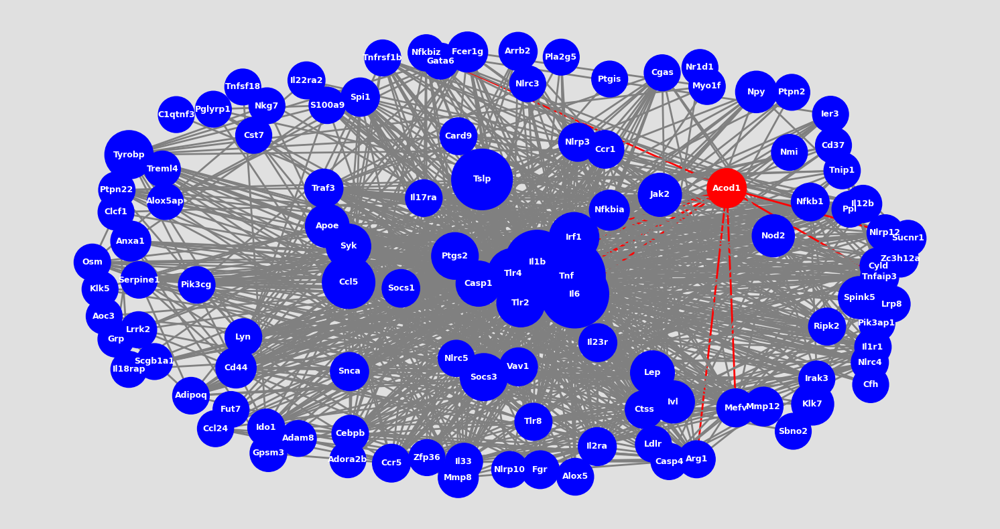

['Acod1', 'Actr2', 'Actr3', 'Adam8', 'Alpk1', 'Anxa1', 'Apoe', 'Arg1', 'Arid5a', 'Arrb2', 'B2m', 'Bcl10', 'Btk', 'Casp1', 'Casp4', 'Ccl17', 'Ccl22', 'Ccl24', 'Ccl5', 'Ccr1', 'Cd14', 'Cd177', 'Cd55', 'Cfh', 'Ch25h', 'Clec4d', 'Clec4e', 'Clec5a', 'Clec7a', 'Coro1a', 'Cyld', 'Dapk1', 'Ddx3x', 'Eif2ak2', 'Fcer1g', 'Fes', 'Fgg', 'Fgr', 'G3bp1', 'Gch1', 'Gsn', 'Hck', 'Ifit2', 'Ifnar2', 'Il12b', 'Il17ra', 'Il18rap', 'Il1rap', 'Il23r', 'Irak3', 'Irf1', 'Jak2', 'Jak3', 'Jchain', 'Klrg1', 'Kynu', 'Lcn2', 'Lep', 'Lrp8', 'Ltf', 'Lyn', 'Map4k2', 'Cgas', 'Mefv', 'Mmp12', 'Mx1', 'Myo1f', 'N4bp1', 'Nkg7', 'Nlrc3', 'Nlrc4', 'Nlrc5', 'Nlrp10', 'Nlrp3', 'Nmi', 'Nod2', 'Nos2', 'Npy', 'Padi4', 'Pglyrp1', 'Pla2g2f', 'Pla2g5', 'Plscr1', 'Prdm1', 'Pstpip1', 'Ptk2b', 'Ptpn2', 'Ptx3', 'Rab20', 'Rab27a', 'Rel', 'Relb', 'Ripk2', 'Rnf19b', 'Rnf39', 'Rsad2', 'S100a9', 'Sla', 'Slamf1', 'Slc11a1', 'Slc15a3', 'Snca', 'Socs1', 'Spi1', 'Srms', 'Stx11', 'Syk', 'Tarm1', 'Tlr2', 'Tlr4', 'Tlr7', 'Tlr8', 'Tnfaip3', 'Tnfrsf14

<Figure size 1100x1100 with 0 Axes>

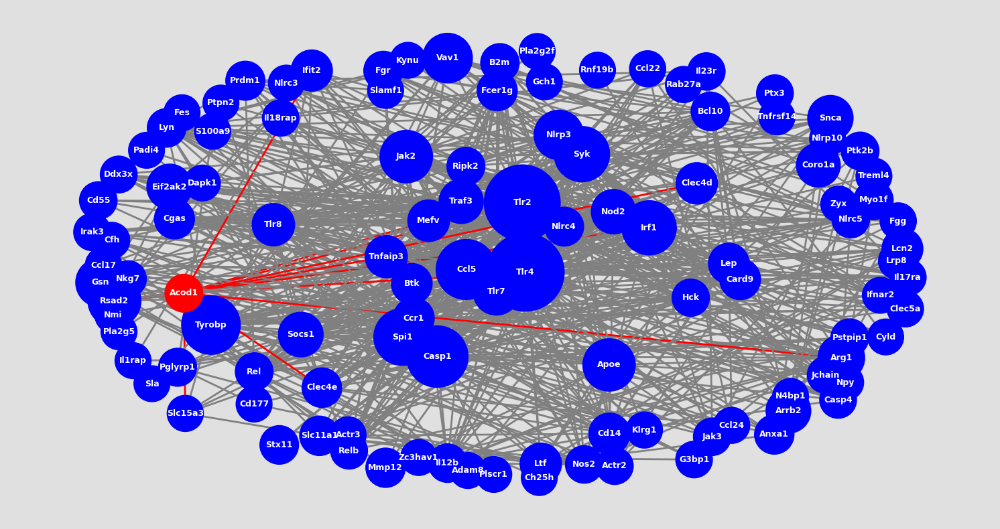

['Acod1', 'Adam8', 'Adipoq', 'Adora2b', 'Akna', 'Alox5', 'Alox5ap', 'Anxa1', 'Aoah', 'Aoc3', 'Apoe', 'C1qtnf3', 'Casp1', 'Casp4', 'Ccl24', 'Ccl5', 'Ccr5', 'Cd44', 'Cebpb', 'Clcf1', 'Cst7', 'Ctss', 'Cyld', 'Daglb', 'Duoxa2', 'Tafa3', 'Fcer1g', 'Fut7', 'Ggt1', 'Gpsm3', 'Ido1', 'Ier3', 'Il12b', 'Il17ra', 'Il1b', 'Il1r1', 'Il22ra2', 'Il2ra', 'Il33', 'Il6', 'Jak2', 'Ldlr', 'Lrrk2', 'Lyn', 'Mefv', 'Metrnl', 'Mmp8', 'Nfkb1', 'Nfkbia', 'Nfkbiz', 'Nkg7', 'Nlrc3', 'Nlrp10', 'Nlrp12', 'Nlrp3', 'Nmi', 'Nod2', 'Npy', 'Nr1d1', 'Osm', 'Pglyrp1', 'Pik3ap1', 'Pik3cg', 'Pla2g5', 'Ptgis', 'Ptgs2', 'Ptpn2', 'S100a9', 'Sbno2', 'Scgb1a1', 'Serpine1', 'Snca', 'Socs3', 'Sucnr1', 'Tlr2', 'Tlr4', 'Tnc', 'Tnf', 'Tnfaip3', 'Tnfrsf1b', 'Tnfsf18', 'Tnip1', 'Tslp', 'Ccn4', 'Zfp36', 'Acod1']


<Figure size 1100x1100 with 0 Axes>

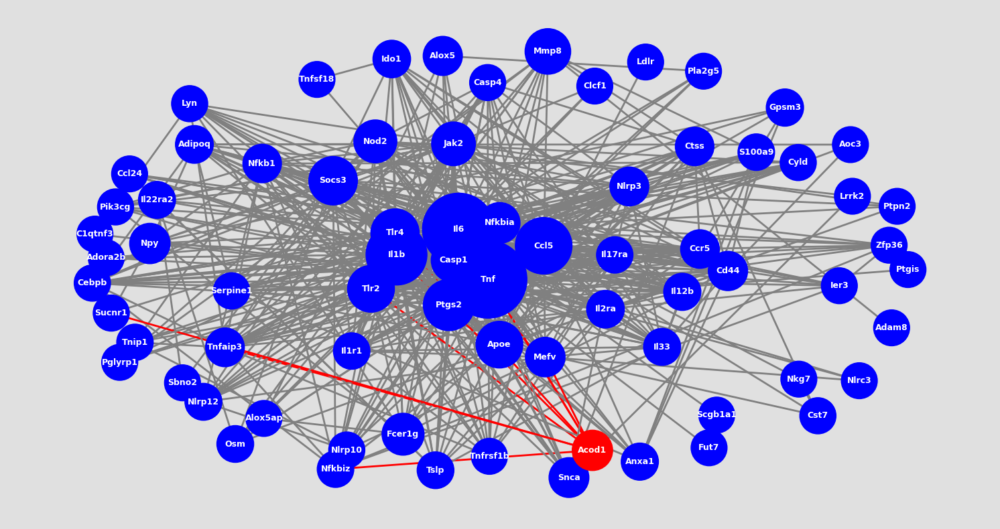

['Acod1', 'Arid5a', 'B2m', 'Bcl10', 'Bdkrb1', 'Casp1', 'Ccl5', 'Cd14', 'Cd55', 'Cd68', 'Cd80', 'Cd86', 'Cebpb', 'Cfh', 'Cxcl10', 'Eif2ak2', 'Gch1', 'Ido1', 'Il12b', 'Il1a', 'Il1b', 'Il1f10', 'Il23r', 'Il6', 'Irak2', 'Irak3', 'Jak2', 'Litaf', 'Ltf', 'Lyn', 'Map2k3', 'Ncf2', 'Nfkb1', 'Nfkbia', 'Nfkbib', 'Nlrc3', 'Nlrp3', 'Nod2', 'Nos2', 'Nr1d1', 'Pde4b', 'Plscr1', 'Ppbp', 'Ptafr', 'Ptger2', 'Ptgs2', 'Ptpn22', 'Rara', 'Ripk2', 'S100a9', 'Sbno2', 'Serpine1', 'Slc11a1', 'Snca', 'Spi1', 'Tlr4', 'Tnf', 'Tnfaip3', 'Tnfrsf1b', 'Tnip1', 'Tnip3', 'Trib1', 'Zc3h12a', 'Zfp36', 'Acod1']


<Figure size 1100x1100 with 0 Axes>

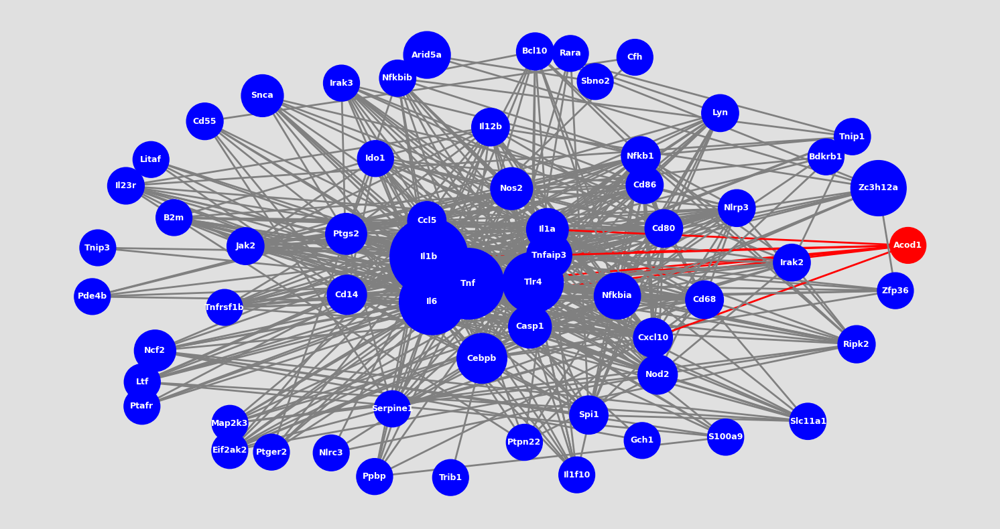

['Acod1', 'Adipoq', 'Adtrp', 'Anxa1', 'Arg1', 'Arrb2', 'Btk', 'Ccr1', 'Cd300lf', 'Cd37', 'Cd44', 'Cd46', 'Cd55', 'Cd68', 'Cd80', 'Cd86', 'Cdk6', 'Cebpb', 'Clec4g', 'Cst7', 'Dgkz', 'Dusp1', 'Tafa3', 'Ripor2', 'Fas', 'Fcer1g', 'Fcrlb', 'Fgl1', 'Fgr', 'Gcsam', 'Grem1', 'Hlx', 'Hmox1', 'Id2', 'Ido1', 'Il12b', 'Il13ra2', 'Il2ra', 'Il33', 'Inpp5d', 'Irak3', 'Irf1', 'Jak3', 'Laptm5', 'Ldlr', 'Lst1', 'Lyn', 'Mafb', 'Mmp12', 'Nckap1l', 'Nfkbid', 'Nlrc3', 'Nlrc5', 'Nmi', 'Nod2', 'Npy', 'Nr1d1', 'Olfm4', 'Pag1', 'Pglyrp1', 'Pla2g2f', 'Ptpn2', 'Ptpn22', 'Ptprc', 'Ptprj', 'Rara', 'Runx1', 'Samsn1', 'Scgb1a1', 'Slamf1', 'Socs1', 'Sox11', 'Spi1', 'Spink5', 'Tarm1', 'Tbc1d10c', 'Thbs1', 'Tigit', 'Tnf', 'Tnfaip3', 'Tnfrsf14', 'Tnfsf18', 'Trib1', 'Tyrobp', 'Ubash3a', 'Zc3h12a', 'Acod1']


<Figure size 1100x1100 with 0 Axes>

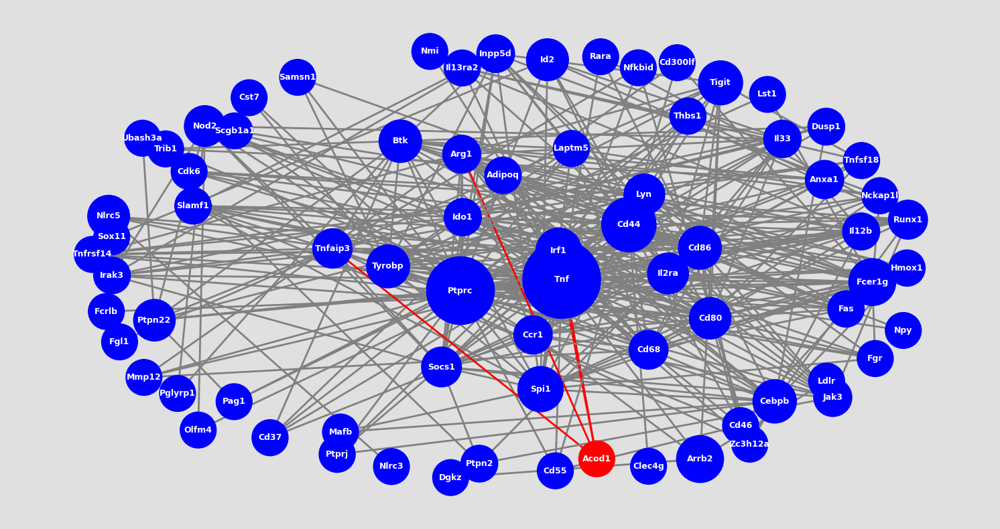

['Acod1', 'Adipoq', 'Alox5', 'Aoah', 'Apoe', 'C1qtnf3', 'Cd44', 'Cst7', 'Cyld', 'Tafa3', 'Ier3', 'Il12b', 'Il22ra2', 'Il2ra', 'Ldlr', 'Mefv', 'Metrnl', 'Nfkb1', 'Nlrc3', 'Nlrp12', 'Nlrp3', 'Nod2', 'Npy', 'Nr1d1', 'Pglyrp1', 'Pla2g5', 'Ptgis', 'Ptpn2', 'Socs3', 'Tnfaip3', 'Tnfrsf1b', 'Zfp36', 'Acod1']


<Figure size 1100x1100 with 0 Axes>

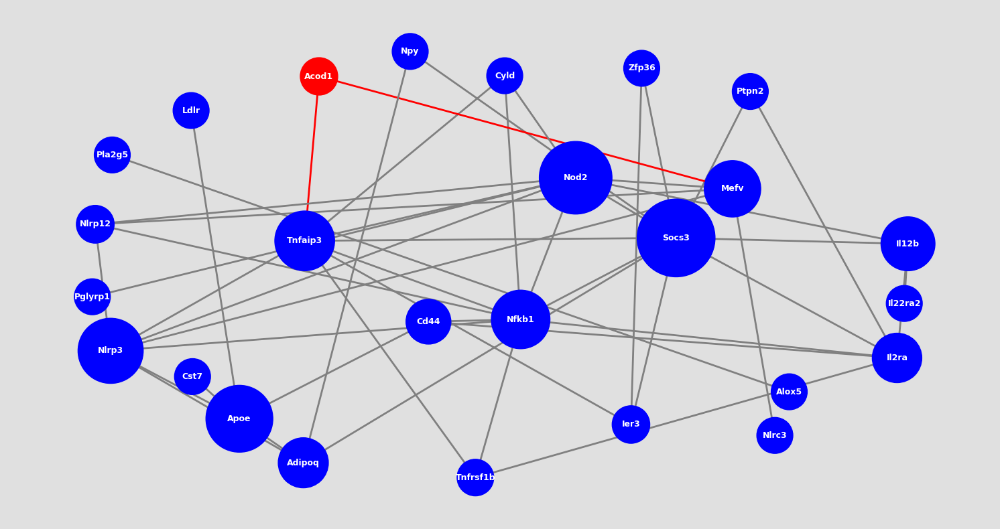

In [16]:
# Top BP in which Acod1 is involved in 
# Regulation of defense response (GO:0031347), Innate immune response (GO:0045087), Regulation of inflammatory response (GO:0050727)
# positive regulation of response to external stimulus, positive regulation of immune response, response to molecule of bacterial origin
# response to lipopolysaccharide, cellular response to molecule of bacterial origin, positive regulation of defense response



# Any pathways in which Acod1 is involved in
# regulation of defense response
protein_list = ["Acod1","Adam8","Adipoq","Adora2b","Akna","Alox5","Alox5ap","Anxa1","Aoah","Aoc3","Apoe","Arg1","Arrb2","C1qtnf3","Casp1","Casp4","Ccl24","Ccl5","Ccr1","Ccr5","Cd37","Cd44","Cebpb","Cfh","Clcf1","Clec7a","Cst7","Ctss","Cyld","Daglb","Duoxa2","Tafa3","Fcer1g","Fgr","Fut7","Gata6","Ggt1","Gpsm3","Grp","Ido1","Ier3","Il12b","Il17ra","Il18rap","Il1b","Il1r1","Il22ra2","Il23r","Il2ra","Il33","Il6","Irak3","Irf1","Ivl","Jak2","Klk5","Klk7","Ldlr","Lep","Lrp8","Lrrk2","Lyn","Cgas","Mefv","Metrnl","Mmp12","Mmp8","Myo1f","N4bp1","Nfkb1","Nfkbia","Nfkbiz","Nkg7","Nlrc3","Nlrc4","Nlrc5","Nlrp10","Nlrp12","Nlrp3","Nmi","Nod2","Npy","Nr1d1","Osm","Pglyrp1","Pik3ap1","Pik3cg","Pla2g5","Plscr1","Ppl","Ptgis","Ptgs2","Ptpn2","Ptpn22","Ripk2","S100a9","Sbno2","Scgb1a1","Serpine1","Snca","Socs1","Socs3","Spi1","Spink5","Sucnr1","Syk","Tlr2","Tlr4","Tlr8","Tnc","Tnf","Tnfaip3","Tnfrsf1b","Tnfsf18","Tnip1","Traf3","Treml4","Tslp","Tyrobp","Vav1","Ccn4","Zc3h12a","Zc3hav1","Zfp36"]
plot_network(protein_list)

# innate immune response
protein_list = ["Acod1","Actr2","Actr3","Adam8","Alpk1","Anxa1","Apoe","Arg1","Arid5a","Arrb2","B2m","Bcl10","Btk","Casp1","Casp4","Ccl17","Ccl22","Ccl24","Ccl5","Ccr1","Cd14","Cd177","Cd55","Cfh","Ch25h","Clec4d","Clec4e","Clec5a","Clec7a","Coro1a","Cyld","Dapk1","Ddx3x","Eif2ak2","Fcer1g","Fes","Fgg","Fgr","G3bp1","Gch1","Gsn","Hck","Ifit2","Ifnar2","Il12b","Il17ra","Il18rap","Il1rap","Il23r","Irak3","Irf1","Jak2","Jak3","Jchain","Klrg1","Kynu","Lcn2","Lep","Lrp8","Ltf","Lyn","Map4k2","Cgas","Mefv","Mmp12","Mx1","Myo1f","N4bp1","Nkg7","Nlrc3","Nlrc4","Nlrc5","Nlrp10","Nlrp3","Nmi","Nod2","Nos2","Npy","Padi4","Pglyrp1","Pla2g2f","Pla2g5","Plscr1","Prdm1","Pstpip1","Ptk2b","Ptpn2","Ptx3","Rab20","Rab27a","Rel","Relb","Ripk2","Rnf19b","Rnf39","Rsad2","S100a9","Sla","Slamf1","Slc11a1","Slc15a3","Snca","Socs1","Spi1","Srms","Stx11","Syk","Tarm1","Tlr2","Tlr4","Tlr7","Tlr8","Tnfaip3","Tnfrsf14","Traf3","Treml4","Trim17","Tyrobp","Vav1","Wfdc3","Zbtb1","Zc3hav1","ZyxAcod1","Actr2","Actr3","Adam8","Alpk1","Anxa1","Apoe","Arg1","Arid5a","Arrb2","B2m","Bcl10","Btk","Casp1","Casp4","Ccl17","Ccl22","Ccl24","Ccl5","Ccr1","Cd14","Cd177","Cd55","Cfh","Ch25h","Clec4d","Clec4e","Clec5a","Clec7a","Coro1a","Cyld","Dapk1","Ddx3x","Eif2ak2","Fcer1g","Fes","Fgg","Fgr","G3bp1","Gch1","Gsn","Hck","Ifit2","Ifnar2","Il12b","Il17ra","Il18rap","Il1rap","Il23r","Irak3","Irf1","Jak2","Jak3","Jchain","Klrg1","Kynu","Lcn2","Lep","Lrp8","Ltf","Lyn","Map4k2","Cgas","Mefv","Mmp12","Mx1","Myo1f","N4bp1","Nkg7","Nlrc3","Nlrc4","Nlrc5","Nlrp10","Nlrp3","Nmi","Nod2","Nos2","Npy","Padi4","Pglyrp1","Pla2g2f","Pla2g5","Plscr1","Prdm1","Pstpip1","Ptk2b","Ptpn2","Ptx3","Rab20","Rab27a","Rel","Relb","Ripk2","Rnf19b","Rnf39","Rsad2","S100a9","Sla","Slamf1","Slc11a1","Slc15a3","Snca","Socs1","Spi1","Srms","Stx11","Syk","Tarm1","Tlr2","Tlr4","Tlr7","Tlr8","Tnfaip3","Tnfrsf14","Traf3","Treml4","Trim17","Tyrobp","Vav1","Wfdc3","Zbtb1","Zc3hav1","Zyx"]
plot_network(protein_list)

# regulation of inflammatory response
protein_list = ["Acod1","Adam8","Adipoq","Adora2b","Akna","Alox5","Alox5ap","Anxa1","Aoah","Aoc3","Apoe","C1qtnf3","Casp1","Casp4","Ccl24","Ccl5","Ccr5","Cd44","Cebpb","Clcf1","Cst7","Ctss","Cyld","Daglb","Duoxa2","Tafa3","Fcer1g","Fut7","Ggt1","Gpsm3","Ido1","Ier3","Il12b","Il17ra","Il1b","Il1r1","Il22ra2","Il2ra","Il33","Il6","Jak2","Ldlr","Lrrk2","Lyn","Mefv","Metrnl","Mmp8","Nfkb1","Nfkbia","Nfkbiz","Nkg7","Nlrc3","Nlrp10","Nlrp12","Nlrp3","Nmi","Nod2","Npy","Nr1d1","Osm","Pglyrp1","Pik3ap1","Pik3cg","Pla2g5","Ptgis","Ptgs2","Ptpn2","S100a9","Sbno2","Scgb1a1","Serpine1","Snca","Socs3","Sucnr1","Tlr2","Tlr4","Tnc","Tnf","Tnfaip3","Tnfrsf1b","Tnfsf18","Tnip1","Tslp","Ccn4","Zfp36"]
plot_network(protein_list)

# Response to lipopolysacharide
protein_list = ["Acod1","Arid5a","B2m","Bcl10","Bdkrb1","Casp1","Ccl5","Cd14","Cd55","Cd68","Cd80","Cd86","Cebpb","Cfh","Cxcl10","Eif2ak2","Gch1","Ido1","Il12b","Il1a","Il1b","Il1f10","Il23r","Il6","Irak2","Irak3","Jak2","Litaf","Ltf","Lyn","Map2k3","Ncf2","Nfkb1","Nfkbia","Nfkbib","Nlrc3","Nlrp3","Nod2","Nos2","Nr1d1","Pde4b","Plscr1","Ppbp","Ptafr","Ptger2","Ptgs2","Ptpn22","Rara","Ripk2","S100a9","Sbno2","Serpine1","Slc11a1","Snca","Spi1","Tlr4","Tnf","Tnfaip3","Tnfrsf1b","Tnip1","Tnip3","Trib1","Zc3h12a","Zfp36"]
plot_network(protein_list)

# Acod1 in negative regulation - negative regulation of immune system process (28th) much lower showing the system is already activated but in scap this is much higher
protein_list = ["Acod1","Adipoq","Adtrp","Anxa1","Arg1","Arrb2","Btk","Ccr1","Cd300lf","Cd37","Cd44","Cd46","Cd55","Cd68","Cd80","Cd86","Cdk6","Cebpb","Clec4g","Cst7","Dgkz","Dusp1","Tafa3","Ripor2","Fas","Fcer1g","Fcrlb","Fgl1","Fgr","Gcsam","Grem1","Hlx","Hmox1","Id2","Ido1","Il12b","Il13ra2","Il2ra","Il33","Inpp5d","Irak3","Irf1","Jak3","Laptm5","Ldlr","Lst1","Lyn","Mafb","Mmp12","Nckap1l","Nfkbid","Nlrc3","Nlrc5","Nmi","Nod2","Npy","Nr1d1","Olfm4","Pag1","Pglyrp1","Pla2g2f","Ptpn2","Ptpn22","Ptprc","Ptprj","Rara","Runx1","Samsn1","Scgb1a1","Slamf1","Socs1","Sox11","Spi1","Spink5","Tarm1","Tbc1d10c","Thbs1","Tigit","Tnf","Tnfaip3","Tnfrsf14","Tnfsf18","Trib1","Tyrobp","Ubash3a","Zc3h12a"]
plot_network(protein_list)

# Acod1 in negative regulation - , negative regulation of inflammatory response(163rd)
protein_list = ["Acod1","Adipoq","Alox5","Aoah","Apoe","C1qtnf3","Cd44","Cst7","Cyld","Tafa3","Ier3","Il12b","Il22ra2","Il2ra","Ldlr","Mefv","Metrnl","Nfkb1","Nlrc3","Nlrp12","Nlrp3","Nod2","Npy","Nr1d1","Pglyrp1","Pla2g5","Ptgis","Ptpn2","Socs3","Tnfaip3","Tnfrsf1b","Zfp36"]
plot_network(protein_list)

['Acod1', 'Nfkb1', 'Il12b', 'Il17ra', 'Il18rap', 'Il1b', 'Il1r1', 'Il22ra2', 'Il23r', 'Il2ra', 'Il33', 'Il6', 'Irf1', 'Jak2', 'Klk5', 'Klk7', 'Nfkb1', 'Nfkbia', 'Nfkbiz', 'Nlrc3', 'Nlrc4', 'Nlrc5', 'Nlrp10', 'Nlrp12', 'Nlrp3', 'Pik3ap1', 'Pik3cg', 'Pla2g5', 'Ptgs2', 'Socs1', 'Socs3', 'Spi1', 'Tlr2', 'Tlr4', 'Tlr8', 'Tnf', 'Tnfaip3', 'Tnfrsf1b', 'Tnfsf18', 'Traf3', 'Acod1']


<Figure size 1100x1100 with 0 Axes>

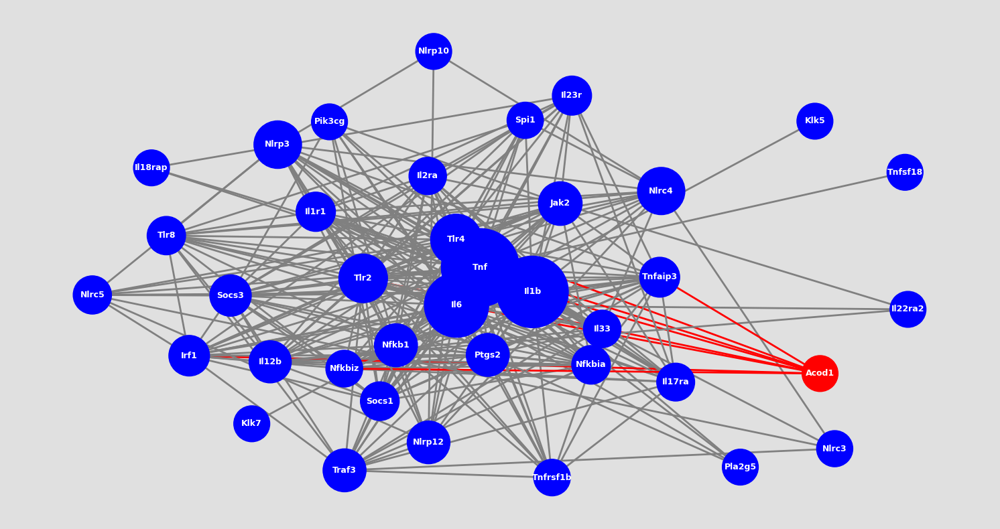

In [17]:
protein_list = ["Acod1","Nfkb1", "Il12b","Il17ra","Il18rap","Il1b","Il1r1","Il22ra2","Il23r","Il2ra","Il33","Il6","Irf1","Jak2","Klk5","Klk7","Nfkb1","Nfkbia","Nfkbiz","Nlrc3","Nlrc4","Nlrc5","Nlrp10","Nlrp12","Nlrp3","Pik3ap1","Pik3cg","Pla2g5","Ptgs2","Socs1","Socs3","Spi1","Tlr2","Tlr4","Tlr8","Tnf","Tnfaip3","Tnfrsf1b","Tnfsf18","Traf3",]
plot_network(protein_list)

# Genes regulated by Nkfb1

['S100a9', 'Ggt1', 'Tnc', 'Adam8', 'Serpine1', 'Clcf1', 'Nlrp3', 'Pglyrp1', 'Il6', 'Osm', 'Ptgs2', 'Acod1', 'Mmp8', 'Nfkb1']


<Figure size 1100x1100 with 0 Axes>

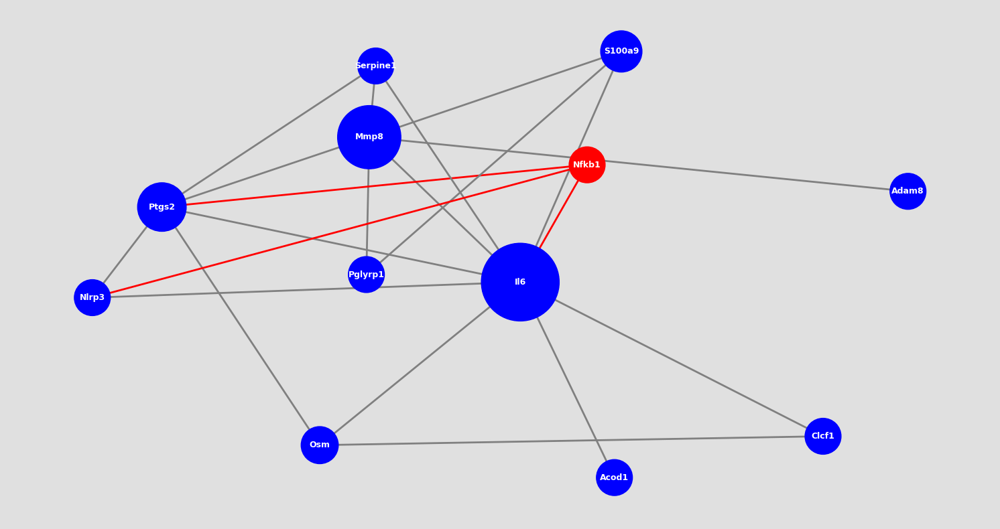

In [7]:
import requests
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

def plot_network(protein_list):
    highlighted_genes = ["Nfkb1"]
    protein_list = protein_list + highlighted_genes
    print(protein_list)

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n')  # pull the text from the response object and split based on new lines
    data = [l.split('\t') for l in lines]  # split each line into its components based on tabs
    # convert to dataframe using the first row as the column names; drop empty, final row
    df = pd.DataFrame(data[1:-1], columns=data[0]) 
    # dataframe with the preferred names of the two proteins and the score of the interaction
    interactions = df[['preferredName_A', 'preferredName_B']]  

    G = nx.Graph(name='Protein Interaction Graph')
    interactions = np.array(interactions)
    for i in range(len(interactions)):
        interaction = interactions[i]
        a = interaction[0]  # protein a node
        b = interaction[1]  # protein b node
        G.add_edge(a, b)  # add edge to graph without weight

    pos = nx.spring_layout(G)  # position the nodes using the spring layout
    plt.figure(figsize=(11, 11), facecolor=[0.7, 0.7, 0.7, 0.4])

    # function to rescale list of values to range [newmin, newmax]
    def rescale(l, newmin, newmax):
        arr = list(l)
        if max(arr) - min(arr) == 0:
            return [newmin] * len(arr)  # Avoid division by zero by assigning the minimum value to all
        return [(x - min(arr)) / (max(arr) - min(arr)) * (newmax - newmin) + newmin for x in arr]

    # use the matplotlib viridis colormap
    graph_colormap = cm.get_cmap('viridis', 12)

    # node color varies with Degree
    c = rescale([G.degree(v) for v in G], 0.0, 0.9) 
    c = [graph_colormap(i) for i in c]

    # node size varies with betweenness centrality - map to range [1500, 7000]
    bc = nx.betweenness_centrality(G)  # betweenness centrality    
    s = rescale([v for v in bc.values()], 1500, 7000)

    pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
    plt.figure(figsize=(19, 10), facecolor=[0.7, 0.7, 0.7, 0.4])

    # Assigning colors to nodes
    node_color = []
    for node in G.nodes():
        if node in highlighted_genes:
            node_color.append('red')
        else:
            node_color.append('blue')

    # Assigning colors to edges
    edge_color = []
    for u, v in G.edges():
        if u in highlighted_genes or v in highlighted_genes:
            edge_color.append('red')
        else:
            edge_color.append('grey')   
    
    
    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color=node_color, edge_color=edge_color, width=2,
                     font_color='white', font_weight='bold', font_size='9')

    plt.axis('off')
    plt.show()
protein_list = ["S100a9", "Ggt1", "Tnc", "Adam8", "Serpine1", "Clcf1", "Nlrp3", "Pglyrp1", "Il6", "Osm", "Ptgs2", "Acod1", "Mmp8"]
plot_network(protein_list)

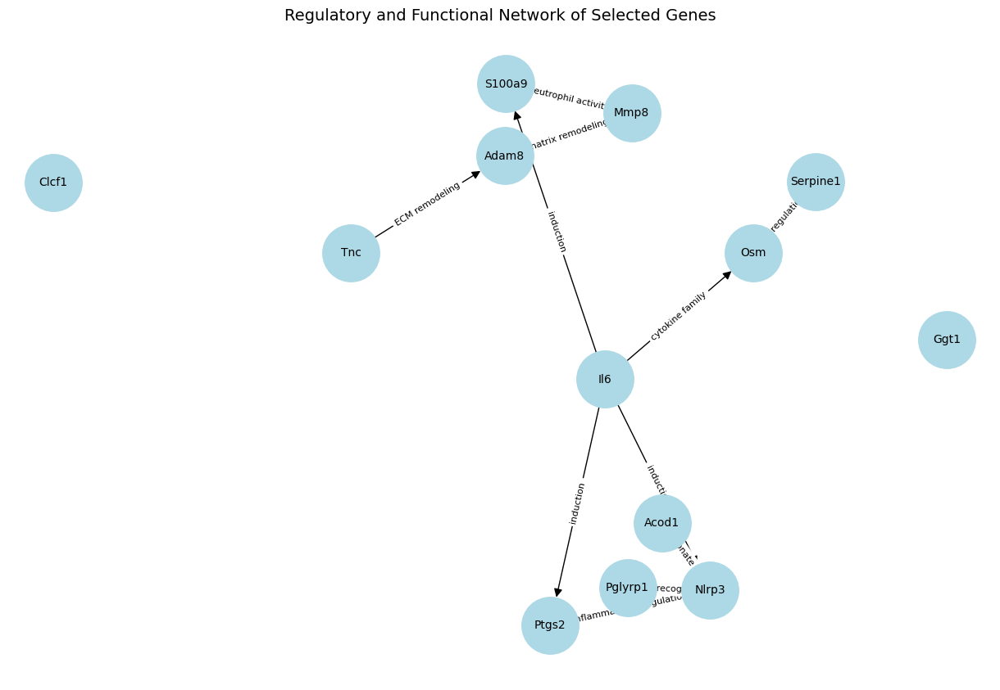

In [8]:
import networkx as nx
import matplotlib.pyplot as plt

# Define gene list
genes = ["S100a9", "Ggt1", "Tnc", "Adam8", "Serpine1", 
         "Clcf1", "Nlrp3", "Pglyrp1", "Il6", "Osm", 
         "Ptgs2", "Acod1", "Mmp8"]

# Define known/potential regulatory or functional relationships (simplified, based on literature)
edges = [
    ("Il6", "Osm", "cytokine family"),
    ("Il6", "Ptgs2", "induction"),
    ("Il6", "S100a9", "induction"),
    ("Il6", "Nlrp3", "induction"),
    ("Osm", "Serpine1", "upregulation"),
    ("Nlrp3", "Ptgs2", "inflammasome regulation"),
    ("Pglyrp1", "Nlrp3", "PAMP recognition"),
    ("Acod1", "Nlrp3", "ROS/itaconate inhibition"),
    ("S100a9", "Mmp8", "neutrophil activity"),
    ("Tnc", "Adam8", "ECM remodeling"),
    ("Adam8", "Mmp8", "matrix remodeling"),
]

# Create graph
G = nx.DiGraph()
G.add_nodes_from(genes)
for src, tgt, label in edges:
    G.add_edge(src, tgt, label=label)

# Draw network
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G, k=0.5, seed=42)
nx.draw(G, pos, with_labels=True, node_size=2500, node_color="lightblue", font_size=10, arrowsize=15)
edge_labels = nx.get_edge_attributes(G, "label")
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)
plt.title("Regulatory and Functional Network of Selected Genes", fontsize=14)
plt.show()


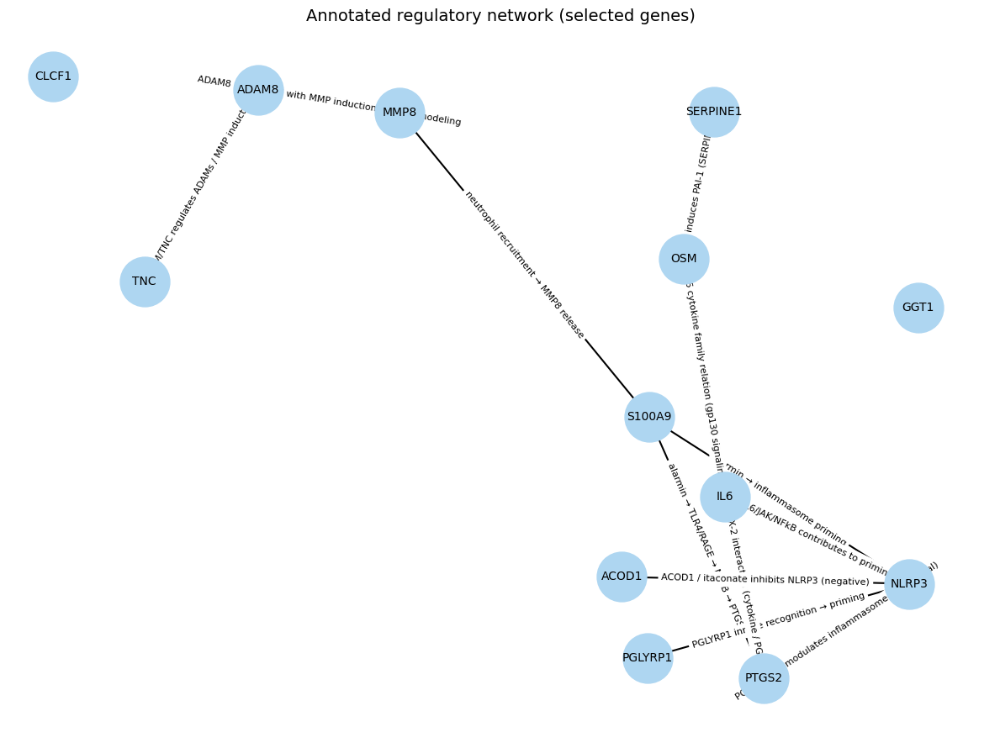

Edge index | Source -> Target | Label | Citations
 0 | S100A9 -> PTGS2 | alarmin → TLR4/RAGE → NFkB → PTGS2 | ['turn0search0', 'turn0search8']
 1 | S100A9 -> NLRP3 | alarmin → inflammasome priming | ['turn0search10', 'turn0search8']
 2 | IL6 -> PTGS2 | IL6 / COX-2 interaction (cytokine / PGE2 loop) | ['turn0search11', 'turn0search19']
 3 | IL6 -> NLRP3 | IL6/JAK/NFkB contributes to priming | ['turn0search10']
 4 | IL6 -> OSM | IL6 cytokine family relation (gp130 signaling) | ['turn0search11']
 5 | OSM -> SERPINE1 | OSM induces PAI-1 (SERPINE1) | ['turn0search12', 'turn0search4']
 6 | PGLYRP1 -> NLRP3 | PGLYRP1 innate recognition → priming | ['turn0search2', 'turn0search15']
 7 | ACOD1 -> NLRP3 | ACOD1 / itaconate inhibits NLRP3 (negative) | ['turn0search1', 'turn0search9']
 8 | S100A9 -> MMP8 | neutrophil recruitment → MMP8 release | ['turn0search14', 'turn0search22']
 9 | TNC -> ADAM8 | ECM/TNC regulates ADAMs / MMP induction | ['turn0search7', 'turn0search23']
10 | ADAM8 -> MMP8 | AD

In [9]:
# network_with_citations.py
import networkx as nx
import matplotlib.pyplot as plt

# Node list
nodes = ["S100A9", "GGT1", "TNC", "ADAM8", "SERPINE1",
         "CLCF1", "NLRP3", "PGLYRP1", "IL6", "OSM",
         "PTGS2", "ACOD1", "MMP8"]

# Edge list with short label and citation tag (web.run ref ids)
edges = [
    ("S100A9", "PTGS2", "alarmin → TLR4/RAGE → NFkB → PTGS2"),
    ("S100A9", "NLRP3", "alarmin → inflammasome priming"),
    ("IL6", "PTGS2", "IL6 / COX-2 interaction (cytokine / PGE2 loop)"),
    ("IL6", "NLRP3", "IL6/JAK/NFkB contributes to priming"),
    ("IL6", "OSM", "IL6 cytokine family relation (gp130 signaling)"),
    ("OSM", "SERPINE1", "OSM induces PAI-1 (SERPINE1)"),
    ("PGLYRP1", "NLRP3", "PGLYRP1 innate recognition → priming"),
    ("ACOD1", "NLRP3", "ACOD1 / itaconate inhibits NLRP3 (negative)"),
    ("S100A9", "MMP8", "neutrophil recruitment → MMP8 release"),
    ("TNC", "ADAM8", "ECM/TNC regulates ADAMs / MMP induction"),
    ("ADAM8", "MMP8", "ADAM8 associated with MMP induction / ECM remodeling"),
    ("PTGS2", "NLRP3", "PGE2/COX-2 modulates inflammasome (contextual)")
]

# Citation mapping (short form: map edge index -> citations)
citations = {
    0: ["turn0search0","turn0search8"],      # S100A9 -> PTGS2
    1: ["turn0search10","turn0search8"],     # S100A9 -> NLRP3
    2: ["turn0search11","turn0search19"],    # IL6 -> PTGS2
    3: ["turn0search10"],                    # IL6 -> NLRP3
    4: ["turn0search11"],                    # IL6 -> OSM (cytokine family link)
    5: ["turn0search12","turn0search4"],     # OSM -> SERPINE1
    6: ["turn0search2","turn0search15"],     # PGLYRP1 -> NLRP3
    7: ["turn0search1","turn0search9"],      # ACOD1 -> NLRP3 (inhibition)
    8: ["turn0search14","turn0search22"],    # S100A9 -> MMP8 (neutrophil)
    9: ["turn0search7","turn0search23"],     # TNC -> ADAM8 / MMP induction
    10:["turn1search1","turn1search2"],      # ADAM8 -> MMP8 (review + experiments)
    11:["turn0search5","turn0search19"]      # PTGS2 -> NLRP3 (modulatory)
}

# Build graph
G = nx.DiGraph()
G.add_nodes_from(nodes)
for idx, (s,t,label) in enumerate(edges):
    G.add_edge(s, t, label=label, citation_idx=idx)

# Draw
plt.figure(figsize=(12,9))
pos = nx.spring_layout(G, k=0.6, seed=42)
nx.draw_networkx_nodes(G, pos, node_color="#AED6F1", node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=10)
nx.draw_networkx_edges(G, pos, arrowstyle='->', arrowsize=18, width=1.5)

# Edge labels
edge_labels = {(u,v): G[u][v]['label'] for u,v in G.edges()}
nx.draw_networkx_edge_labels(G, pos, edge_labels=edge_labels, font_size=8)

plt.title("Annotated regulatory network (selected genes)", fontsize=14)
plt.axis('off')
plt.tight_layout()
plt.show()

# Print edge -> citation mapping (human-readable)
print("Edge index | Source -> Target | Label | Citations")
for idx, (s,t,label) in enumerate(edges):
    print(f"{idx:2d} | {s} -> {t} | {label} | {citations[idx]}")


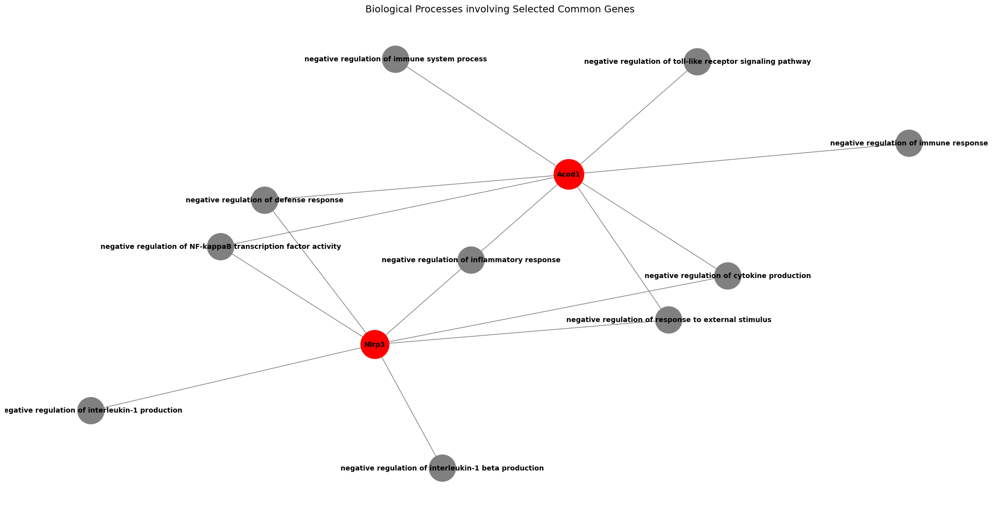

In [17]:
"""The logic here is to understand which genes invloved in inflammatory BP that is common between Spalax and mouse and what are the other BPs
Currently the top 50"""

import pandas as pd
from collections import Counter
import os
import networkx as nx
import matplotlib.pyplot as plt

path = "C:/projects/Final Rat Trans Project Result2023/blindmolerat_rnaseqanalysis-2024/DMBA/Results_10092025_f2.5_p0.01_SELECTED/entrezID/"
os.chdir(path)

# Load CSV
df = pd.read_csv("S.control-S.wound/GeneOntologyBP.csv") 
#df = pd.read_csv("MM.control-M.wound/GeneOntologyBP.csv") 
df["gene_list"] = df["geneID"].str.split("/")

# Your common genes
a = "Acod1/Adam8/Adora2b/Anxa1/Apoa1/Apoe/C1qtnf3/Ccr5/Clcf1/Cnr2/Daglb/Duoxa2/Ggt1/Il17ra/Il1r1/Il6/Mefv/Mmp8/Nfkbiz/Nlrp12/Nlrp3/Nod2/Nr1d1/Osm/Pglyrp1/Ptgis/Ptgs2/S100a9/Serpine1/Snca/Socs3/Tlr2/Tnc/Tnf/Tnfaip3/Tslp/Zfp36".split("/")
# Mouse
b = "Acod1/Ada/Adam8/Adipoq/Adora1/Adora3/Agt/Aoc3/Ccl24/Clcf1/Esr1/Fcer1a/Ffar4/Ggt1/Gpx2/Il1b/Il22ra2/Il33/Il6/Isl1/Lpl/Mmp8/Nlrp3/Npy/Nr1d2/Osm/Pbk/Pglyrp1/Pla2g5/Ptger3/Ptgs2/S100a9/Scgb1a1/Serpine1/Sucnr1/Tnc/Tnfsf11/Tnfsf4/Wfdc1/Ccn4".split("/")
a = set(a)
b = set(b)

common_genes = ["Acod1", "Nlrp3"] #a & b
# Filter rows containing at least one common gene
df_filtered = df[df["gene_list"].apply(lambda genes: any(g in genes for g in common_genes))]
#import pdb; pdb.set_trace()
df_filtered = df_filtered.iloc[0:] #20

# Count occurrences for all common genes
all_genes = [gene for sublist in df_filtered["gene_list"] for gene in sublist if gene in common_genes]
gene_counts = Counter(all_genes)


# --- Build network ---
G = nx.Graph()

# Add BP nodes
for _, row in df_filtered.iterrows():
    bp = row['Description']
    if bp.startswith("negative"):
                G.add_node(bp, color='grey', size=1500)
    for g in row['gene_list']:
        if g in common_genes:
            if g not in G:
                G.add_node(g, color='red', size=0)  # temporary size
            if bp.startswith("negative"):
                import pdb
                #pdb.set_trace()
                G.add_edge(g, bp)

# Update gene node sizes proportional to number of BP connections
for g in common_genes:
    if g in G:
        num_edges = len([n for n in G.neighbors(g)])
        G.nodes[g]['size'] = 300 + 200 * num_edges  # base + multiplier

# Node attributes
colors = [G.nodes[n]['color'] for n in G.nodes]
sizes = [G.nodes[n]['size'] for n in G.nodes]

# Plot network
plt.figure(figsize=(20, 10))
pos = nx.spring_layout(G, k=0.9, seed=4)
pos = nx.kamada_kawai_layout(G)
nx.draw(G, pos, with_labels=True, node_color=colors, node_size=sizes,
        font_size=10, font_weight='bold', edge_color='gray')
plt.title("Biological Processes involving Selected Common Genes", fontsize=14)

plt.show()

In [10]:
import networkx as nx

def filter_bps_with_all_genes(G, gene_list, bp_nodes=None):
    """
    Return BPs that are connected to *all* genes in gene_list.

    Parameters
    ----------
    G : networkx.Graph
        Bipartite graph with genes and BPs as nodes.
    gene_list : list
        List of gene nodes (subset of nodes in G).
    bp_nodes : list or None
        Optional list of BP nodes (subset of nodes in G).
        If None, infer BP nodes as those not in gene_list.

    Returns
    -------
    valid_bps : list
        List of BP nodes connected to all genes.
    """
    if bp_nodes is None:
        bp_nodes = [n for n in G.nodes if n not in gene_list]

    valid_bps = []
    for bp in bp_nodes:
        neighbors = set(G.neighbors(bp))
        if all(gene in neighbors for gene in gene_list):
            valid_bps.append(bp)

    return valid_bps


# -----------------------
# Example usage
# -----------------------
# Suppose G is already built, with nodes: genes and BP terms
gene_list = ["Il6", "Osm", "Ptgs2", "Acod1"]

bps_with_all = filter_bps_with_all_genes(G, gene_list)

print("BPs connected to ALL genes in list:")
for bp in bps_with_all:
    print(bp)


BPs connected to ALL genes in list:


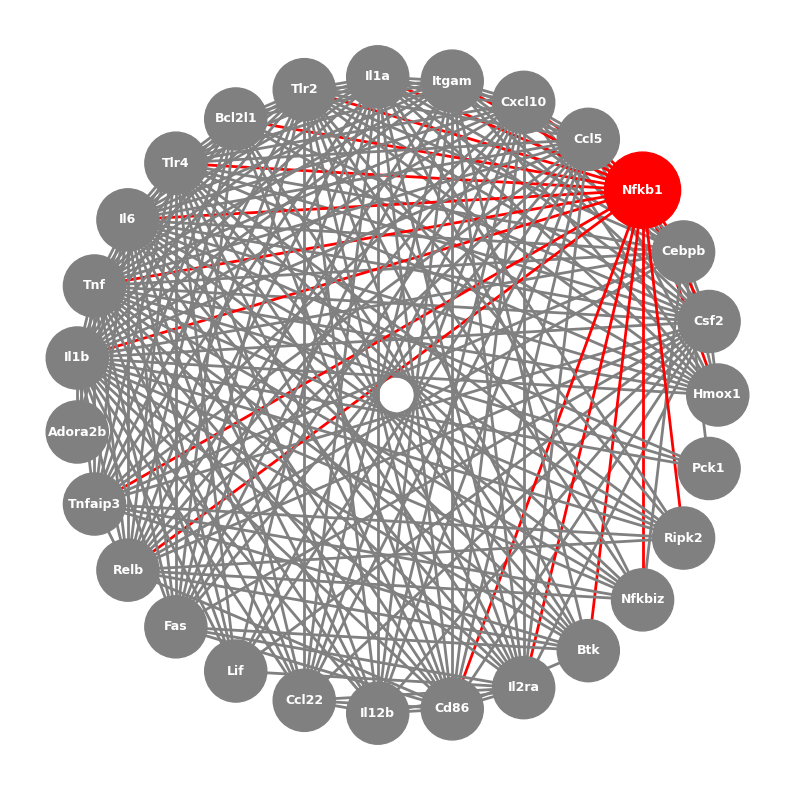

In [19]:
import requests
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

def plot_network(protein_list):
    highlighted_genes = ["Nfkb1"]
    protein_list = protein_list + highlighted_genes

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n')
    data = [l.split('\t') for l in lines if l]
    df = pd.DataFrame(data[1:], columns=data[0])
    interactions = df[['preferredName_A', 'preferredName_B']].values

    G = nx.Graph(name='Protein Interaction Graph')
    for interaction in interactions:
        a = interaction[0]
        b = interaction[1]
        G.add_edge(a, b)

    # Assign node sizes
    node_sizes = {node: 3000 if node == 'Nfkb1' else 2000 for node in G.nodes()}

    # Circular layout
    pos = nx.circular_layout(G)

    plt.figure(figsize=(10, 10))

    # Assigning colors to nodes
    node_color = ['red' if node in highlighted_genes else 'grey' for node in G.nodes()]

    # Assigning colors to edges
    edge_color = ['red' if u in highlighted_genes or v in highlighted_genes else 'grey' for u, v in G.edges()]   

    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=[node_sizes[node] for node in G.nodes()],
                     node_color=node_color, edge_color=edge_color, width=2, font_color='white',
                     font_weight='bold', font_size=9)

    plt.axis('off')
    plt.show()

protein_list = ["Adora2b","Bcl2l1","Btk","Cd86","Cebpb","Csf2","Fas","Hmox1","Cxcl10","Il12b","Il1a",
                "Il1b","Il2ra","Il6","Itgam","Lif","Pck1","Relb","Ccl22","Ccl5","Tlr4","Tnf","Tnfaip3",
                "Tlr2","Nfkbiz","Ripk2"]

plot_network(protein_list)


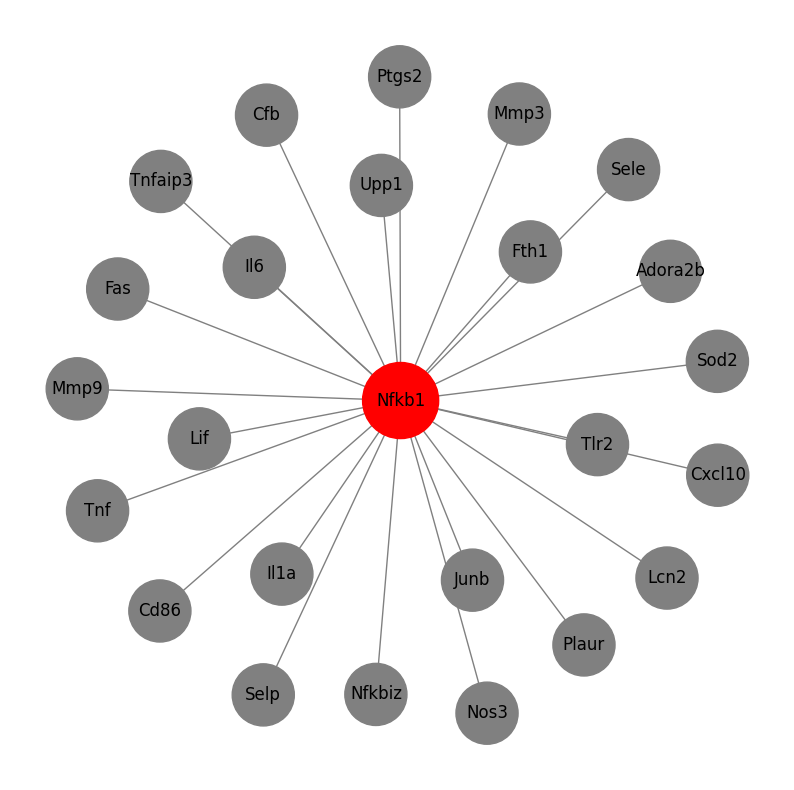

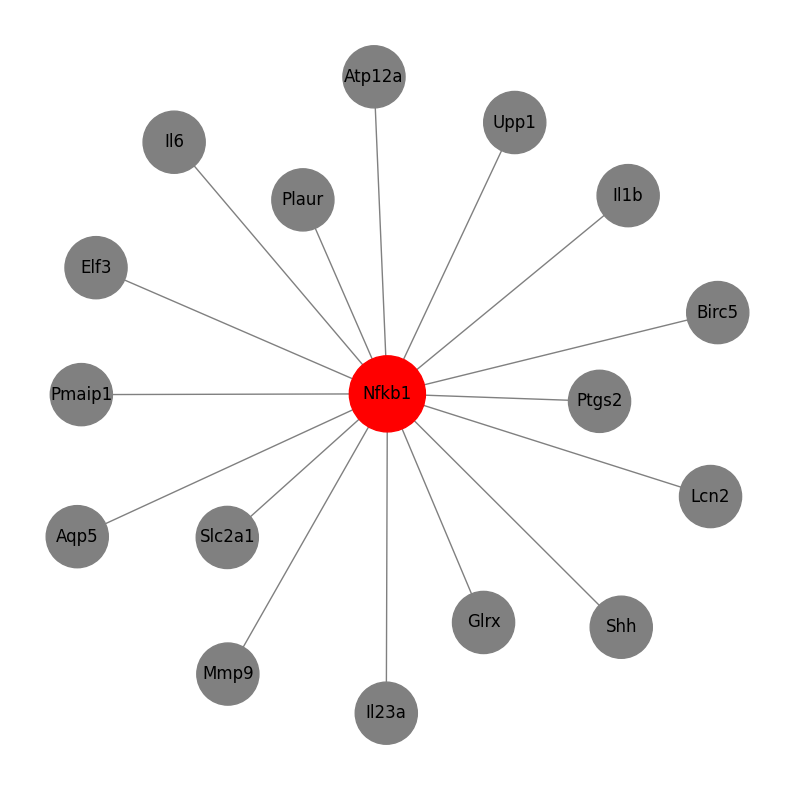

34

In [15]:
import networkx as nx
import matplotlib.pyplot as plt

def flatten_list(nested_list):
    return [item for sublist in nested_list for item in sublist]


def plot_network(protein_list, highlight):
    G = nx.Graph()

    # Add nodes for proteins
    for protein in protein_list:
        G.add_edge(highlight, protein)

    # Set node sizes
    node_sizes = {highlight: 3000}
    for protein in protein_list:
        node_sizes[protein] = 2000

    # Set node colors
    node_colors = ['red' if node == highlight else 'grey' for node in G.nodes()]

    pos = nx.spring_layout(G, seed=42)  # Layout the nodes using a spring layout algorithm

    plt.figure(figsize=(10, 10))

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=[node_sizes[node] for node in G.nodes()])
    nx.draw_networkx_edges(G, pos, edge_color='grey', width=1.0)
    nx.draw_networkx_labels(G, pos, font_size=12, font_color='black', font_family='sans-serif')

    plt.axis('off')
    plt.show()

protein_list1 = [
    "Adora2b", "Cd86", "Fas", "Fth1", "Cfb", "Cxcl10", "Il1a", "Il6", 
    "Junb", "Lcn2", "Lif", "Mmp3", "Mmp9", "Nos3", "Plaur", "Ptgs2", 
    "Sele", "Selp", "Sod2", "Tnf", "Tnfaip3", "Upp1", "Tlr2", "Nfkbiz"
] # Spalax
plot_network(protein_list1, 'Nfkb1')

protein_list2 = [
    "Birc5", "Aqp5", "Elf3", "Il1b", "Il6", "Lcn2", "Mmp9", "Plaur", 
    "Ptgs2", "Shh", "Slc2a1", "Upp1", "Pmaip1", "Il23a", "Glrx", "Atp12a"
] #Mouse

plot_network(protein_list2, 'Nfkb1')

# Total number of protein regualted by Nfkb and Rela
len(set(protein_list1 + protein_list2))

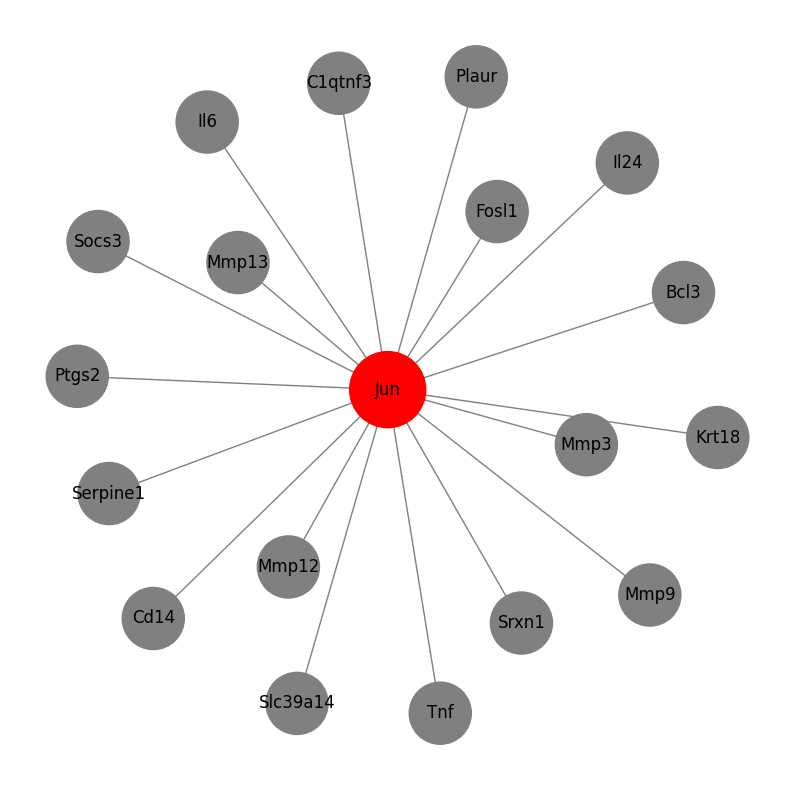

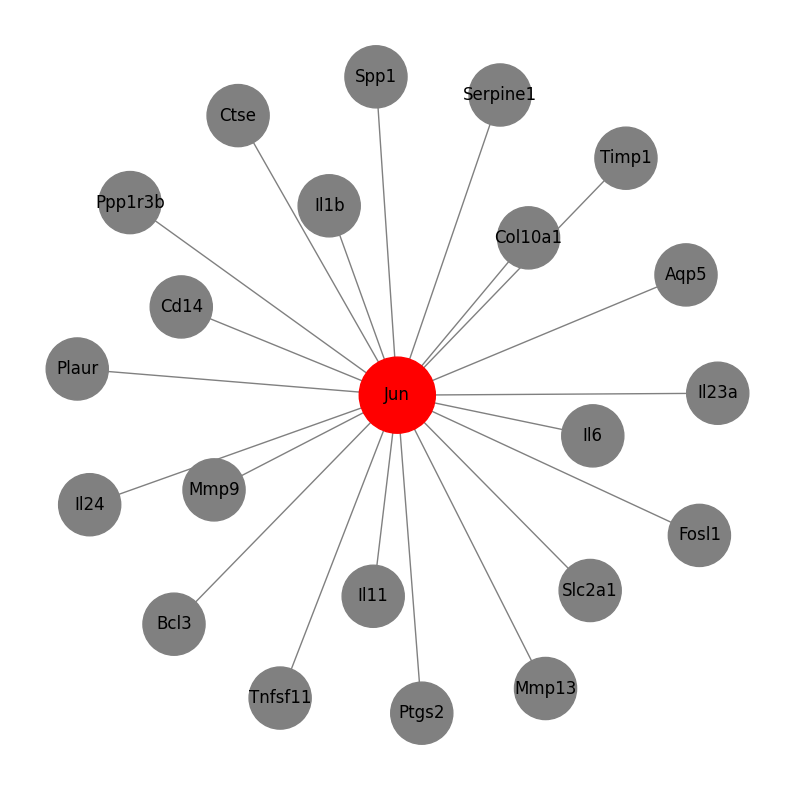

29

In [17]:
import networkx as nx
import matplotlib.pyplot as plt

def flatten_list(nested_list):
    return [item for sublist in nested_list for item in sublist]


def plot_network(protein_list, highlight):
    G = nx.Graph()

    # Add nodes for proteins
    for protein in protein_list:
        G.add_edge(highlight, protein)

    # Set node sizes
    node_sizes = {highlight: 3000}
    for protein in protein_list:
        node_sizes[protein] = 2000

    # Set node colors
    node_colors = ['red' if node == highlight else 'grey' for node in G.nodes()]

    pos = nx.spring_layout(G, seed=42)  # Layout the nodes using a spring layout algorithm

    plt.figure(figsize=(10, 10))

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=[node_sizes[node] for node in G.nodes()])
    nx.draw_networkx_edges(G, pos, edge_color='grey', width=1.0)
    nx.draw_networkx_labels(G, pos, font_size=12, font_color='black', font_family='sans-serif')

    plt.axis('off')
    plt.show()

protein_list1 = [
    "Bcl3", "Cd14", "Socs3", "Fosl1", "Il6", "Krt18", "Mmp12", "Mmp13",
    "Mmp3", "Mmp9", "Serpine1", "Plaur", "Ptgs2", "Tnf", "Srxn1",
    "C1qtnf3", "Il24", "Slc39a14"
]  # Spalax
plot_network(protein_list1, 'Jun')

protein_list2 = [
    "Aqp5", "Bcl3", "Cd14", "Col10a1", "Ctse", "Fosl1", "Il11", "Il1b", 
    "Il6", "Mmp13", "Mmp9", "Serpine1", "Plaur", "Ptgs2", "Slc2a1", 
    "Spp1", "Timp1", "Tnfsf11", "Il23a", "Il24", "Ppp1r3b"
] # Mouse


plot_network(protein_list2, 'Jun')

# Total number of protein regualted by Nfkb and Rela
len(set(protein_list1 + protein_list2))

## Prove there is a negative regulation of inflammation (Scab)

In Spalax scab stage we see there is a negative regulation of immune system process (GO:0002683) with 37 genes invovled

['Acod1', 'Adtrp', 'Arg1', 'Cd274', 'Cd46', 'Cd55', 'Cd80', 'Cd84', 'Cdk6', 'Col3a1', 'Fas', 'Gcsam', 'Grem1', 'Havcr2', 'Igf2', 'Il12b', 'Il2ra', 'Inpp4b', 'Lax1', 'Nfkbid', 'Pag1', 'Pdcd1', 'Pglyrp1', 'Pten', 'Ptprj', 'Rc3h1', 'Runx1', 'Runx3', 'Samsn1', 'Tarm1', 'Thbs1', 'Tigit', 'Tnf', 'Tnfrsf14', 'Tnfsf18', 'Ubash3a', 'Wasl', 'Acod1']


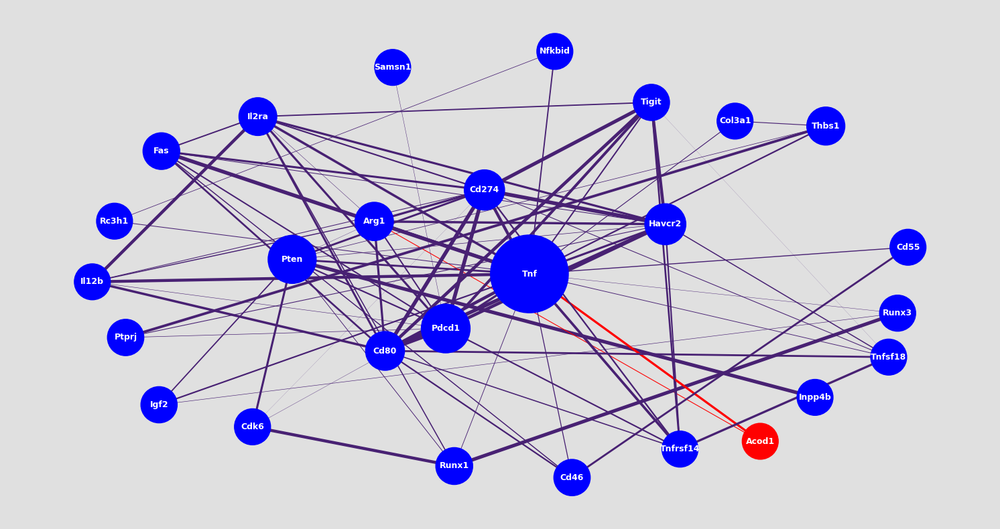

['Acod1', 'Bag6', 'Bmx', 'Cd28', 'Clec4d', 'Clec7a', 'Esr1', 'Ffar2', 'Fpr1', 'Fpr2', 'Fyb', 'Gcsam', 'Havcr2', 'Lax1', 'Lcp2', 'Ltf', 'Mef2c', 'Nfkbid', 'Nr4a3', 'Ptprj', 'Rc3h1', 'Rps6ka3', 'Rsad2', 'Slc46a2', 'Themis', 'Tlr8', 'Tnip3', 'Treml4', 'Ubash3a', 'Wnk1', 'Acod1']


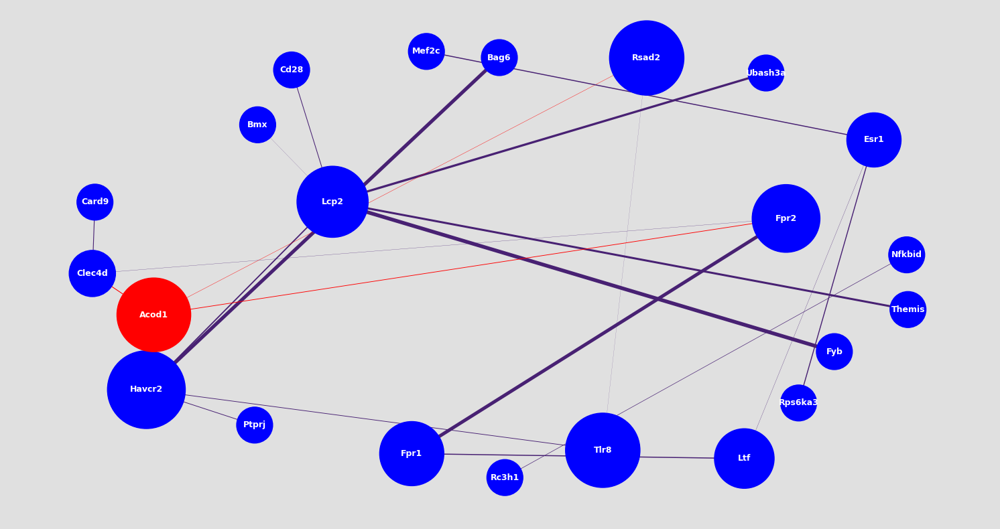

['Acod1', 'Bag6', 'Bmx', 'Cd274', 'Cd28', 'Cd46', 'Cd55', 'Clec7a', 'Ereg', 'Ffar2', 'Fpr1', 'Fpr2', 'Fyb', 'Gcsam', 'Havcr2', 'Il12b', 'Il1b', 'Il23a', 'Il23r', 'Il6', 'Lax1', 'Lcp2', 'Mef2c', 'Nfkbid', 'Nr4a3', 'Ptprj', 'Rc3h1', 'Rsad2', 'Slc11a1', 'Themis', 'Tlr8', 'Tnf', 'Ubash3a', 'Wnk1', 'Acod1']


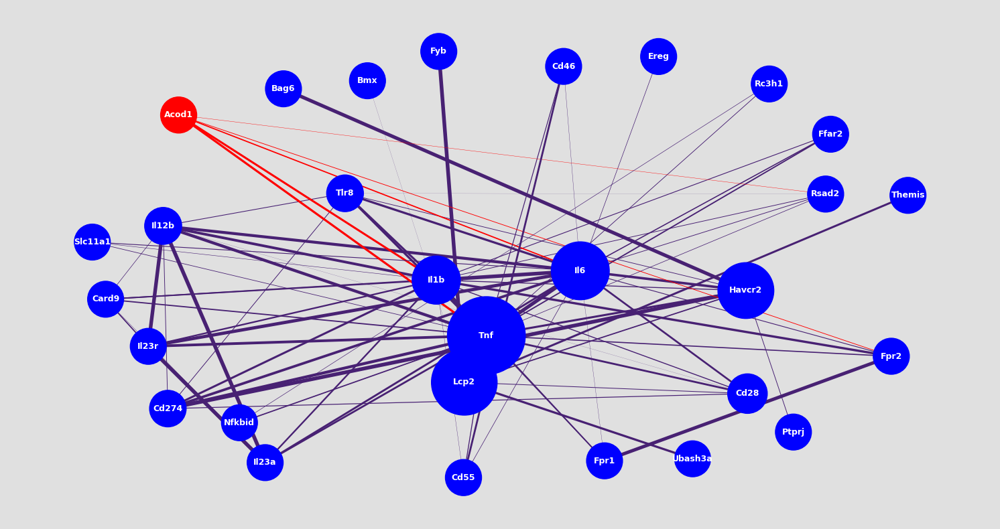

In [21]:
import requests
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.cm as cm

def plot_network(protein_list):
    """
    Node size of each node represents its betweenness centrality. Betweenness centrality is a measure of the importance of a node in a network based on the number of shortest paths that pass through the node. 
    Edge weights typically correspond to the confidence score or probability that a particular interaction is biologically relevant.
    """
    highlighted_genes = ["Acod1"]
    protein_list = protein_list + highlighted_genes
    print(protein_list)

    proteins = '%0d'.join(protein_list)
    url = 'https://string-db.org/api/tsv/network?identifiers=' + proteins + '&species=10090'
    r = requests.get(url)

    lines = r.text.split('\n')  # pull the text from the response object and split based on new lines
    data = [l.split('\t') for l in lines]  # split each line into its components based on tabs
    # convert to dataframe using the first row as the column names; drop empty, final row
    df = pd.DataFrame(data[1:-1], columns=data[0]) 
    # dataframe with the preferred names of the two proteins and the score of the interaction
    interactions = df[['preferredName_A', 'preferredName_B', 'score']]  

    G = nx.Graph(name='Protein Interaction Graph')
    interactions = np.array(interactions)
    for i in range(len(interactions)):
        interaction = interactions[i]
        a = interaction[0]  # protein a node
        b = interaction[1]  # protein b node
        w = float(interaction[2])  # score as weighted edge where high scores = low weight
        G.add_weighted_edges_from([(a, b, w)])  # add weighted edge to graph

    # function to rescale list of values to range [newmin, newmax]
    def rescale(l, newmin, newmax):
        arr = list(l)
        if max(arr) - min(arr) == 0:
            return [newmin] * len(arr)  # Avoid division by zero by assigning the minimum value to all
        return [(x - min(arr)) / (max(arr) - min(arr)) * (newmax - newmin) + newmin for x in arr]

    # use the matplotlib viridis colormap
    graph_colormap = cm.get_cmap('viridis', 12)

    # node color varies with Degree
    c = rescale([G.degree(v) for v in G], 0.0, 0.9) 
    c = [graph_colormap(i) for i in c]

    # node size varies with betweenness centrality - map to range [1500, 7000]
    bc = nx.betweenness_centrality(G)  # betweenness centrality
    s = rescale([v for v in bc.values()], 1500, 7000)

    # edge width shows 1-weight to convert cost back to strength of interaction 
    ew = rescale([float(G[u][v]['weight']) for u, v in G.edges], 0.1, 4)

    pos = nx.spring_layout(G, k=2)  # Adjust the k value to prevent node overlap
    plt.figure(figsize=(19, 10), facecolor=[0.7, 0.7, 0.7, 0.4])

    # Assigning colors to nodes
    node_color = []
    for node in G.nodes():
        if node in highlighted_genes:
            node_color.append('red')
        else:
            node_color.append('blue')

    # Assigning colors to edges
    edge_color = []
    for u, v in G.edges():
        if u in highlighted_genes or v in highlighted_genes:
            edge_color.append('red')
        else:
            edge_color.append(graph_colormap(rescale([float(G[u][v]['weight'])], 0.1, 1)[0]))

    nx.draw_networkx(G, pos=pos, with_labels=True, node_size=s, node_color=node_color, edge_color=edge_color, width=ew,
                     font_color='white', font_weight='bold', font_size='9')

    plt.axis('off')
    plt.show()

# negative regulation of immune system process (GO:0002683)
protein_list = ["Acod1","Adtrp","Arg1","Cd274","Cd46","Cd55","Cd80","Cd84","Cdk6","Col3a1","Fas","Gcsam","Grem1","Havcr2","Igf2","Il12b","Il2ra","Inpp4b","Lax1","Nfkbid","Pag1","Pdcd1","Pglyrp1","Pten","Ptprj","Rc3h1","Runx1","Runx3","Samsn1","Tarm1","Thbs1","Tigit","Tnf","Tnfrsf14","Tnfsf18","Ubash3a","Wasl"]
plot_network(protein_list)

# immune response-regulating signaling pathway GO:0002764
protein_list = ["Acod1","Bag6","Bmx","Cd28","Clec4d","Clec7a","Esr1","Ffar2","Fpr1","Fpr2","Fyb","Gcsam","Havcr2","Lax1","Lcp2","Ltf","Mef2c","Nfkbid","Nr4a3","Ptprj","Rc3h1","Rps6ka3","Rsad2","Slc46a2","Themis","Tlr8","Tnip3","Treml4","Ubash3a","Wnk1"]
plot_network(protein_list)

# positive regulation of immune response
protein_list =   ["Acod1","Bag6","Bmx","Cd274","Cd28","Cd46","Cd55","Clec7a","Ereg","Ffar2","Fpr1","Fpr2","Fyb","Gcsam","Havcr2","Il12b","Il1b","Il23a","Il23r","Il6","Lax1","Lcp2","Mef2c","Nfkbid","Nr4a3","Ptprj","Rc3h1","Rsad2","Slc11a1","Themis","Tlr8","Tnf","Ubash3a","Wnk1"]
plot_network(protein_list)


['Acod1', 'Adtrp', 'Arg1', 'Cd274', 'Cd46', 'Cd55', 'Cd80', 'Cd84', 'Cdk6', 'Col3a1', 'Fas', 'Gcsam', 'Grem1', 'Havcr2', 'Igf2', 'Il12b', 'Il2ra', 'Inpp4b', 'Lax1', 'Nfkbid', 'Pag1', 'Pdcd1', 'Pglyrp1', 'Pten', 'Ptprj', 'Rc3h1', 'Runx1', 'Runx3', 'Samsn1', 'Tarm1', 'Thbs1', 'Tigit', 'Tnf', 'Tnfrsf14', 'Tnfsf18', 'Ubash3a', 'Wasl', 'Acod1']


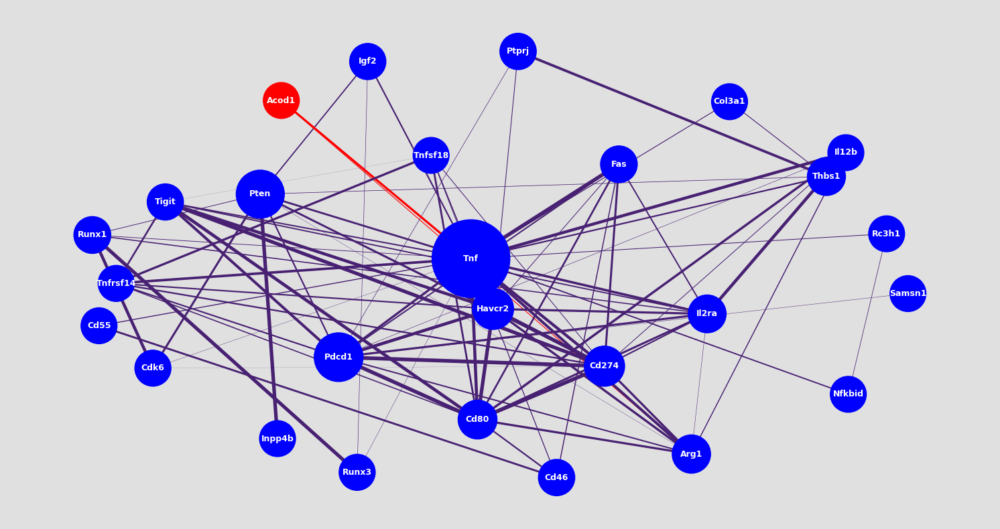

In [22]:
# negative regulation of immune system process (GO:0002683)
protein_list = ["Acod1","Adtrp","Arg1","Cd274","Cd46","Cd55","Cd80","Cd84","Cdk6","Col3a1","Fas","Gcsam","Grem1","Havcr2","Igf2","Il12b","Il2ra","Inpp4b","Lax1","Nfkbid","Pag1","Pdcd1","Pglyrp1","Pten","Ptprj","Rc3h1","Runx1","Runx3","Samsn1","Tarm1","Thbs1","Tigit","Tnf","Tnfrsf14","Tnfsf18","Ubash3a","Wasl"]
plot_network(protein_list)

### References

1. Visualizing protein interaction networks in Python. Accessed on 12th, June, 2024 (https://towardsdatascience.com/visualizing-protein-networks-in-python-58a9b51be9d5)

In [13]:
os.getcwd()

'C:\\projects\\Final Rat Trans Project Result2023\\blindmolerat_rnaseqanalysis-2021\\notebooks'

In [21]:
import pandas as pd

# Load the DEGs data
file_path = 'C:/projects/Final Rat Trans Project Result2023/FinalProjectWorkAugust/DMBA/Results/genesymbol/S.control-S.wound/S.control-S.wound_genes.csv'
deg_df = pd.read_csv(file_path)

# Display the first few rows of the dataframe to understand its structure
print(deg_df.head())

import pandas as pd
import requests
import json
import mygene
import matplotlib.pyplot as plt
from bioservices.kegg import KEGG

# Load the DEGs data
deg_df = pd.read_csv(file_path)

# Display the first few rows of the dataframe to understand its structure
print(deg_df.head())

# Extract relevant columns
gene_symbols = deg_df['GeneSymbol']
logFC = deg_df['logFC']
p_values = deg_df['PValue']

# Initialize KEGG
k = KEGG()
k.organism = "mmu"  # Mouse

# List of key pathways related to inflammation and immune response
pathways = {
    'mmu04668': 'TNF signaling pathway',
    'mmu04060': 'Cytokine-cytokine receptor interaction',
    'mmu04620': 'Toll-like receptor signaling pathway',
    'mmu05152': 'Tuberculosis',
    'mmu04621': 'NOD-like receptor signaling pathway'
}

# Function to get pathway data from KEGG
def get_pathway_data(pathway_id):
    pathway = k.get(pathway_id)
    pathway_data = k.parse(pathway)
    return pathway_data

# Get pathway data for each pathway
pathway_data = {pathway_id: get_pathway_data(pathway_id) for pathway_id in pathways.keys()}

# Initialize mygene
mg = mygene.MyGeneInfo()

# Function to get gene IDs for gene symbols
def get_gene_ids(gene_symbols):
    result = mg.querymany(gene_symbols, scopes='symbol', fields='entrezgene', species='mouse')
    gene_ids = {entry['query']: entry['entrezgene'] for entry in result if 'entrezgene' in entry}
    return gene_ids

# Get gene IDs for DEGs
deg_gene_ids = get_gene_ids(gene_symbols)
print(deg_gene_ids)

# Function to map DEGs to pathways
def map_degs_to_pathways(deg_gene_ids, pathway_data):
    pathway_genes = {}
    for pathway_id, data in pathway_data.items():
        genes_in_pathway = []
        for entry in data['GENE'].keys():
            gene_id = int(entry.split()[0])
            if gene_id in deg_gene_ids.values():
                genes_in_pathway.append((gene_id, data['GENE'][entry][0]))
        pathway_genes[pathway_id] = genes_in_pathway
    return pathway_genes

# Map DEGs to pathways
deg_pathway_mapping = map_degs_to_pathways(deg_gene_ids, pathway_data)
print(deg_pathway_mapping)

# Visualize the pathways with highlighted DEGs
def visualize_pathways(deg_pathway_mapping, pathways):
    for pathway_id, genes in deg_pathway_mapping.items():
        print(f"Pathway: {pathways[pathway_id]}")
        for gene in genes:
            print(f"Gene ID: {gene[0]}, Gene Symbol: {gene[1]}")
        print("\n")

visualize_pathways(deg_pathway_mapping, pathways)


  GeneSymbol  GeneID     logFC    logCPM        PValue
0     A4galt  239559  4.670146  4.629084  6.852331e-08
1      Aadac   67758 -7.251523  4.409586  5.853910e-04
2    Aadacl3  230883 -5.525713  2.765103  2.009763e-03
3     Abca13  268379  6.572787  5.117218  4.919271e-08
4      Abcd2   26874 -3.206533  5.249922  5.746969e-06
  GeneSymbol  GeneID     logFC    logCPM        PValue
0     A4galt  239559  4.670146  4.629084  6.852331e-08
1      Aadac   67758 -7.251523  4.409586  5.853910e-04
2    Aadacl3  230883 -5.525713  2.765103  2.009763e-03
3     Abca13  268379  6.572787  5.117218  4.919271e-08
4      Abcd2   26874 -3.206533  5.249922  5.746969e-06
Creating directory C:\Users\rahul\AppData\Local\bioservices\bioservices\Cache 
Welcome to Bioservices
It looks like you do not have a configuration file.
We are creating one with default values in C:\Users\rahul\AppData\Local\bioservices\bioservices\bioservices.cfg .
Done


3 input query terms found dup hits:	[('Arhgap26', 2), ('Ddit3', 2), ('Eppk1', 2)]
28 input query terms found no hit:	['Fam196b', 'Fam19a3', 'Fam46a', 'Fam46c', 'Fam49a', 'Fam49b', 'Fam57b', 'Fam65b', 'Fam71f2', 'Fyb',


{'A4galt': '239559', 'Aadac': '67758', 'Aadacl3': '230883', 'Abca13': '268379', 'Abcd2': '26874', 'Abi1': '11308', 'Abi3bp': '320712', 'Abl2': '11352', 'Ablim3': '319713', 'Acacb': '100705', 'Acap1': '216859', 'Acbd5': '74159', 'Acer1': '171168', 'Ackr2': '59289', 'Acod1': '16365', 'Acsbg1': '94180', 'Acsl5': '433256', 'Acsm5': '272428', 'Acss1': '68738', 'Acta1': '11459', 'Actb': '11461', 'Actc1': '11464', 'Actr2': '66713', 'Actr3': '74117', 'Adad1': '21744', 'Adam12': '11489', 'Adam19': '11492', 'Adam8': '11501', 'Adamts4': '240913', 'Adgre5': '26364', 'Adgrf4': '78249', 'Adgrg3': '54672', 'Adgrg5': '382045', 'Adipoq': '11450', 'Adipor1': '72674', 'Adm2': '223780', 'Adora2b': '11541', 'Adra1a': '11549', 'Adra2c': '11553', 'Adrb1': '11554', 'Adtrp': '109254', 'Agfg1': '15463', 'Akap12': '83397', 'Akap5': '238276', 'Akirin1': '68050', 'Akna': '100182', 'Aknad1': '329738', 'Akr1b10': '67861', 'Alas2': '11656', 'Aldh16a1': '69748', 'Aldh1a1': '11668', 'Aldh1b1': '72535', 'Aldh8a1': '2373

In [35]:
pathway_data.values()

dict_values([{'ENTRY': 'mmu04668                    Pathway', 'NAME': ['TNF signaling pathway - Mus musculus (house mouse)'], 'DESCRIPTION': 'Tumor necrosis factor (TNF), as a critical cytokine, can induce a wide range of intracellular signal pathways including apoptosis and cell survival as well as inflammation and immunity. Activated TNF is assembled to a homotrimer and binds to its receptors (TNFR1, TNFR2) resulting in the trimerization of TNFR1 or TNFR2. TNFR1 is expressed by nearly all cells and is the major receptor for TNF (also called TNF-alpha). In contrast, TNFR2 is expressed in limited cells such as CD4 and CD8 T lymphocytes, endothelial cells, microglia, oligodendrocytes, neuron subtypes, cardiac myocytes, thymocytes and human mesenchymal stem cells. It is the receptor for both TNF and LTA (also called TNF-beta). Upon binding of the ligand, TNFR mediates the association of some adaptor proteins such as TRADD or TRAF2, which in turn initiate recruitment of signal transducers